# 1. Identitas Proyek

## Analisis Prioritas Risiko Vulnerability pada CISA KEV Menggunakan CVSS, EPSS, dan Profil Karakteristik Teknis

**Nama:** Ander Gibran Siregar
**NIM:** E1E124028
**Mata Kuliah:** Data Science

### Latar belakang
CISA Known Exploited Vulnerabilities (KEV) berisi vulnerability yang telah diketahui dieksploitasi di dunia nyata. NVD melengkapi data tersebut dengan skor CVSS dan karakteristik teknis vulnerability, sedangkan EPSS memberikan probabilitas eksploitasi pada 30 hari ke depan. Ketiga sumber tersebut digabung menggunakan `cveID`.

 seluruh CVE dalam populasi penelitian ini sudah masuk KEV. Karena itu analisis tidak bertujuan memprediksi apakah vulnerability akan dieksploitasi, melainkan mencari pola dan profil yang berbeda **di dalam populasi vulnerability yang sama-sama telah terbukti dieksploitasi**.

### Sumber data
- CISA KEV: `https://www.cisa.gov/sites/default/files/feeds/known_exploited_vulnerabilities.json`
- NVD API: `https://services.nvd.nist.gov/rest/json/cves/2.0`
- EPSS API: `https://api.first.org/data/v1/epss`
- Penyimpanan hasil ETL: MySQL database `airflow_db`

# 2. Pertanyaan Bisnis

### Q1 — Basic
**Vendor dan produk teknologi apa saja yang paling mendominasi katalog celah keamanan yang aktif tereksploitasi (CISA KEV)?**

Fokus EDA: `vendorProject` dan `product`.

### Q2 — Analisis
**Bagaimana karakteristik sebaran tingkat keparahan teknis (NVD) dibandingkan dengan probabilitas ancaman nyata (EPSS) pada celah keamanan tersebut?**

Fokus EDA: `cvssScore` dan `epssScore`.

> Catatan istilah: EPSS adalah probabilitas eksploitasi menurut model EPSS untuk 30 hari berikutnya, bukan bukti bahwa eksploitasi telah terjadi. Bukti eksploitasi pada penelitian ini berasal dari keanggotaan CVE di KEV.

### Q3 — Analisis
**Seberapa besar ketergantungan para peretas pada interaksi pengguna (`userInteraction`) saat mengeksploitasi celah keamanan dengan jalur serangan yang berbeda (`attackVector`)?**

Fokus EDA: hubungan `attackVector` × `userInteraction`.

> Analisis ini menggambarkan pola pada vulnerability yang teramati di KEV, bukan perilaku seluruh hacker secara umum.

### Q4 — Analisis + dasar Model AI
**Apakah vulnerability yang telah masuk CISA KEV menunjukkan profil karakteristik yang berbeda berdasarkan tingkat keparahan, probabilitas eksploitasi, karakteristik serangan, dan dampaknya?**

Q4 **harus dijawab lebih dahulu melalui EDA**. Hasil EDA Q4 kemudian digunakan untuk menentukan feature engineering dan penerapan K-Means pada bagian Model AI.

# 3. Import Packages/Libraries

Semua import diletakkan dalam **satu cell** sesuai struktur tugas. Cell kode berikutnya tidak melakukan import tambahan.

In [7]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mysql.connector

from IPython.display import display
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    silhouette_score,
    silhouette_samples,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
})

print("Semua packages berhasil dimuat.")

Semua packages berhasil dimuat.


# 4. Data Wrangling

Urutan tahap:

- **Gathering** → mengambil ketiga tabel dari MySQL.
- **Assessing** → memeriksa kualitas data **sebelum cleaning**, satu tabel demi satu tabel.
- **Cleaning** → standardisasi, perbaikan tipe data, penghapusan duplikat, lalu menggabungkan ketiga tabel.
- Setelah cleaning, dilakukan **assessment ulang** untuk membandingkan kondisi sebelum dan sesudah.

Notebook menggunakan database MySQL hasil proses Airflow, bukan CSV.

## 4.1 Gathering

Koneksi berikut menggunakan MySQL lokal sesuai konfigurasi proyek.

In [8]:
DB_CONFIG = {
    "host": "localhost",
    "port": 3307,
    "database": "airflow_db",
    "user": "root",
    "password": "root",
}

conn = mysql.connector.connect(**DB_CONFIG)
print("Koneksi ke MySQL berhasil.")

Koneksi ke MySQL berhasil.


In [9]:
def load_mysql_table(connection, table_name):
    cursor = connection.cursor()
    cursor.execute(f"SELECT * FROM {table_name}")
    rows = cursor.fetchall()
    columns = [desc[0] for desc in cursor.description]
    cursor.close()
    return pd.DataFrame(rows, columns=columns)


df_kev = load_mysql_table(conn, "kev_vulnerabilities")
df_nvd = load_mysql_table(conn, "nvd_vulnerabilities")
df_epss = load_mysql_table(conn, "epss_vulnerabilities")

print(f"KEV  : {df_kev.shape[0]:,} baris × {df_kev.shape[1]} kolom")
print(f"NVD  : {df_nvd.shape[0]:,} baris × {df_nvd.shape[1]} kolom")
print(f"EPSS : {df_epss.shape[0]:,} baris × {df_epss.shape[1]} kolom")

KEV  : 1,733 baris × 12 kolom
NVD  : 1,733 baris × 15 kolom
EPSS : 1,733 baris × 4 kolom


### Data KEV

Seluruh data sudah berada di `df_kev`. Ditampilkan 10 baris pertama sebagai pemeriksaan awal; bukan berarti hanya 10 baris yang digunakan.

In [10]:
display(df_kev.head(10))

,cveID,vendorProject,product,vulnerabilityName,dateAdded,shortDescription,requiredAction,dueDate,knownRansomwareCampaignUse,forensicTriage,notes,cwes
0,CVE-2002-0367,Microsoft,Windows,Microsoft Windows Privilege Escalation Vulnera...,2022-03-03,smss.exe debugging subsystem in Microsoft Wind...,Apply updates per vendor instructions.,2022-03-24,Unknown,No,https://nvd.nist.gov/vuln/detail/CVE-2002-0367,
1,CVE-2004-0210,Microsoft,Windows,Microsoft Windows Privilege Escalation Vulnera...,2022-03-03,A privilege elevation vulnerability exists in ...,Apply updates per vendor instructions.,2022-03-24,Unknown,No,https://nvd.nist.gov/vuln/detail/CVE-2004-0210,CWE-120
2,CVE-2004-1464,Cisco,IOS,Cisco IOS Denial-of-Service Vulnerability,2023-05-19,Cisco IOS contains an unspecified vulnerabilit...,Apply updates per vendor instructions.,2023-06-09,Unknown,No,https://sec.cloudapps.cisco.com/security/cente...,
3,CVE-2005-2773,Hewlett Packard (HP),OpenView Network Node Manager,HP OpenView Network Node Manager Remote Code E...,2022-03-25,HP OpenView Network Node Manager could allow a...,Apply updates per vendor instructions.,2022-04-15,Unknown,No,https://nvd.nist.gov/vuln/detail/CVE-2005-2773,
4,CVE-2006-1547,Apache,Struts 1,Apache Struts 1 ActionForm Denial-of-Service V...,2022-01-21,ActionForm in Apache Struts versions before 1....,Apply updates per vendor instructions.,2022-07-21,Unknown,No,https://nvd.nist.gov/vuln/detail/CVE-2006-1547,
5,CVE-2006-2492,Microsoft,Word,Microsoft Word Malformed Object Pointer Vulner...,2022-06-08,Microsoft Word and Microsoft Works Suites cont...,Apply updates per vendor instructions.,2022-06-22,Unknown,No,https://nvd.nist.gov/vuln/detail/CVE-2006-2492,CWE-120
6,CVE-2007-0671,Microsoft,Office,Microsoft Office Excel Remote Code Execution V...,2025-08-12,Microsoft Office Excel contains a remote code ...,"Apply mitigations per vendor instructions, fol...",2025-09-02,Unknown,No,https://learn.microsoft.com/en-us/security-upd...,
7,CVE-2007-3010,Alcatel,OmniPCX Enterprise,Alcatel OmniPCX Enterprise Remote Code Executi...,2022-04-15,masterCGI in the Unified Maintenance Tool in A...,Apply updates per vendor instructions.,2022-05-06,Unknown,No,https://nvd.nist.gov/vuln/detail/CVE-2007-3010,CWE-20
8,CVE-2007-5659,Adobe,Acrobat and Reader,Adobe Acrobat and Reader Buffer Overflow Vulne...,2022-06-08,Adobe Acrobat and Reader contain a buffer over...,Apply updates per vendor instructions.,2022-06-22,Unknown,No,https://nvd.nist.gov/vuln/detail/CVE-2007-5659,CWE-119
9,CVE-2008-0015,Microsoft,Windows,Microsoft Windows Video ActiveX Control Remot...,2026-02-17,Microsoft Windows Video ActiveX Control contai...,"Apply mitigations per vendor instructions, fol...",2026-03-10,Unknown,No,https://web.archive.org/web/20110305211119/htt...,


### Data NVD

In [11]:
display(df_nvd.head(10))

,cveID,description,published,lastModified,cvssScore,severity,attackVector,attackComplexity,privilegesRequired,userInteraction,scope,confidentialityImpact,integrityImpact,availabilityImpact,cwe
0,CVE-2002-0367,smss.exe debugging subsystem in Windows NT and...,2002-06-25 04:00:00,2026-06-16 21:57:18,7.8,HIGH,LOCAL,LOW,LOW,NONE,UNCHANGED,HIGH,HIGH,HIGH,CWE-269
1,CVE-2004-0210,The POSIX component of Microsoft Windows NT an...,2004-08-06 04:00:00,2026-06-16 22:05:10,7.8,HIGH,LOCAL,LOW,LOW,NONE,UNCHANGED,HIGH,HIGH,HIGH,CWE-120
2,CVE-2004-1464,Cisco IOS 12.2(15) and earlier allows remote a...,2004-12-31 05:00:00,2026-06-16 22:07:45,5.9,MEDIUM,NETWORK,HIGH,NONE,NONE,UNCHANGED,NONE,NONE,HIGH,CWE-400
3,CVE-2005-2773,HP OpenView Network Node Manager 6.2 through 7...,2005-09-02 23:03:00,2026-06-16 22:15:39,9.8,CRITICAL,NETWORK,LOW,NONE,NONE,UNCHANGED,HIGH,HIGH,HIGH,CWE-77
4,CVE-2006-1547,ActionForm in Apache Software Foundation (ASF)...,2006-03-30 22:02:00,2026-06-16 22:23:11,7.5,HIGH,NETWORK,LOW,NONE,NONE,UNCHANGED,NONE,NONE,HIGH,NVD-CWE-Other
5,CVE-2006-2492,Buffer overflow in Microsoft Word in Office 20...,2006-05-20 00:02:00,2026-06-16 22:25:09,8.8,HIGH,NETWORK,LOW,NONE,REQUIRED,UNCHANGED,HIGH,HIGH,HIGH,CWE-120
6,CVE-2007-0671,Unspecified vulnerability in Microsoft Excel 2...,2007-02-03 01:28:00,2026-06-16 22:36:02,8.8,HIGH,NETWORK,LOW,NONE,REQUIRED,UNCHANGED,HIGH,HIGH,HIGH,NVD-CWE-noinfo
7,CVE-2007-3010,masterCGI in the Unified Maintenance Tool in A...,2007-09-18 21:17:00,2026-06-16 22:40:52,9.8,CRITICAL,NETWORK,LOW,NONE,NONE,UNCHANGED,HIGH,HIGH,HIGH,"CWE-77, NVD-CWE-noinfo"
8,CVE-2007-5659,Multiple buffer overflows in Adobe Reader and ...,2008-02-12 19:00:00,2026-06-16 22:46:35,7.8,HIGH,LOCAL,LOW,NONE,REQUIRED,UNCHANGED,HIGH,HIGH,HIGH,CWE-120
9,CVE-2008-0015,Stack-based buffer overflow in the CComVariant...,2009-07-07 23:30:00,2026-06-16 22:48:45,8.8,HIGH,NETWORK,LOW,NONE,REQUIRED,UNCHANGED,HIGH,HIGH,HIGH,"CWE-119, CWE-121"


### Data EPSS

In [12]:
display(df_epss.head(10))

,cveID,epssScore,percentile,scoreDate
0,CVE-2002-0367,0.04919000,0.91815000,2026-09-28
1,CVE-2004-0210,0.07214000,0.94110000,2026-09-28
2,CVE-2004-1464,0.04840000,0.91698000,2026-09-28
3,CVE-2005-2773,0.74592000,0.99485000,2026-09-28
4,CVE-2006-1547,0.54635000,0.98988000,2026-09-28
5,CVE-2006-2492,0.48107000,0.98819000,2026-09-28
6,CVE-2007-0671,0.43241000,0.98683000,2026-09-28
7,CVE-2007-3010,0.97385000,0.99897000,2026-09-28
8,CVE-2007-5659,0.87423000,0.99753000,2026-09-28
9,CVE-2008-0015,0.76733000,0.99532000,2026-09-28


### Pemeriksaan kolom aktual

Kolom diperiksa berdasarkan hasil tabel yang benar-benar tersimpan di MySQL agar notebook tidak bergantung pada asumsi nama kolom.

In [13]:
for name, df in [("KEV", df_kev), ("NVD", df_nvd), ("EPSS", df_epss)]:
    print(f"\n{name} columns ({len(df.columns)}):")
    print(df.columns.tolist())


KEV columns (12):
['cveID', 'vendorProject', 'product', 'vulnerabilityName', 'dateAdded', 'shortDescription', 'requiredAction', 'dueDate', 'knownRansomwareCampaignUse', 'forensicTriage', 'notes', 'cwes']

NVD columns (15):
['cveID', 'description', 'published', 'lastModified', 'cvssScore', 'severity', 'attackVector', 'attackComplexity', 'privilegesRequired', 'userInteraction', 'scope', 'confidentialityImpact', 'integrityImpact', 'availabilityImpact', 'cwe']

EPSS columns (4):
['cveID', 'epssScore', 'percentile', 'scoreDate']


### Verifikasi cakupan CVE antartabel

Karena `cveID` adalah join key, kita cek lebih dahulu apakah seluruh CVE KEV sudah mempunyai data NVD dan EPSS.

In [14]:
def normalized_ids(df):
    return set(df["cveID"].dropna().astype(str).str.strip().str.upper())

kev_ids = normalized_ids(df_kev)
nvd_ids = normalized_ids(df_nvd)
epss_ids = normalized_ids(df_epss)

print(f"CVE KEV : {len(kev_ids):,}")
print(f"CVE NVD : {len(nvd_ids):,}")
print(f"CVE EPSS: {len(epss_ids):,}")

print(f"KEV tanpa NVD : {len(kev_ids - nvd_ids):,}")
print(f"KEV tanpa EPSS: {len(kev_ids - epss_ids):,}")

CVE KEV : 1,733
CVE NVD : 1,733
CVE EPSS: 1,733
KEV tanpa NVD : 0
KEV tanpa EPSS: 0


### Menutup koneksi database

Setelah seluruh tabel berhasil dimuat ke DataFrame, koneksi ditutup. Analisis berikutnya dilakukan pada data yang sudah berada di memori notebook.

In [15]:
conn.close()
print("Koneksi MySQL ditutup.")

Koneksi MySQL ditutup.


## 4.2 Assessing — sebelum Cleaning

Setiap tabel dinilai **satu per satu** dengan empat hal utama:

1. ukuran data (`shape`)
2. struktur data (`info()`)
3. statistik deskriptif (`describe(include='all')`)
4. missing value dan duplicate

In [16]:
def assess_table(name, df):
    print("=" * 75)
    print(f"ASSESSMENT: {name}")
    print("=" * 75)
    print("Shape:", df.shape)
    print("\nInfo:")
    df.info()
    print("\nDescribe:")
    display(df.describe(include="all").T)
    print("\nMissing values:")
    missing = df.isna().sum().sort_values(ascending=False)
    display(missing[missing > 0].to_frame("missing_count"))
    if missing.sum() == 0:
        print("Tidak ada missing value.")
    print("\nDuplicate rows:", int(df.duplicated().sum()))
    if "cveID" in df.columns:
        print("Duplicate cveID:", int(df["cveID"].astype(str).str.strip().str.upper().duplicated().sum()))


assess_table("KEV", df_kev)

ASSESSMENT: KEV
Shape: (1733, 12)

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1733 entries, 0 to 1732
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   cveID                       1733 non-null   object
 1   vendorProject               1733 non-null   object
 2   product                     1733 non-null   object
 3   vulnerabilityName           1733 non-null   object
 4   dateAdded                   1733 non-null   object
 5   shortDescription            1733 non-null   object
 6   requiredAction              1733 non-null   object
 7   dueDate                     1733 non-null   object
 8   knownRansomwareCampaignUse  1733 non-null   object
 9   forensicTriage              1733 non-null   object
 10  notes                       1733 non-null   object
 11  cwes                        1733 non-null   object
dtypes: object(12)
memory usage: 162.6+ KB

Describe:


,count,unique,top,freq
cveID,1733,1733,CVE-2026-9586,1
vendorProject,1733,284,Microsoft,389
product,1733,699,Windows,172
vulnerabilityName,1733,1388,Microsoft Win32k Privilege Escalation Vulnerab...,23
dateAdded,1733,481,2021-11-03,287
shortDescription,1733,1645,Google Chromium V8 Engine contains a type conf...,9
requiredAction,1733,46,Apply updates per vendor instructions.,893
dueDate,1733,504,2022-05-03,189
knownRansomwareCampaignUse,1733,2,Unknown,1372
forensicTriage,1733,2,No,1659



Missing values:


,missing_count


Tidak ada missing value.

Duplicate rows: 0
Duplicate cveID: 0


In [17]:
assess_table("NVD", df_nvd)

ASSESSMENT: NVD
Shape: (1733, 15)

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1733 entries, 0 to 1732
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   cveID                  1733 non-null   object        
 1   description            1733 non-null   object        
 2   published              1733 non-null   datetime64[ns]
 3   lastModified           1733 non-null   datetime64[ns]
 4   cvssScore              1733 non-null   object        
 5   severity               1733 non-null   object        
 6   attackVector           1733 non-null   object        
 7   attackComplexity       1733 non-null   object        
 8   privilegesRequired     1733 non-null   object        
 9   userInteraction        1733 non-null   object        
 10  scope                  1733 non-null   object        
 11  confidentialityImpact  1733 non-null   object        
 12  integrityImpact      

,count,unique,top,freq,mean,min,25%,50%,75%,max
cveID,1733,1733,CVE-2026-9586,1,NaN,NaN,NaN,NaN,NaN,NaN
description,1733,1650,Microsoft Exchange Server Remote Code Executio...,9,NaN,NaN,NaN,NaN,NaN,NaN
published,1733,NaN,NaN,NaN,2021-04-16 02:51:37.924985600,2002-06-25 04:00:00,2019-03-24 15:29:00,2021-10-08 22:15:08,2024-08-22 19:15:09,2026-10-01 20:17:24
lastModified,1733,NaN,NaN,NaN,2026-06-30 19:27:29.724754688,2026-06-16 21:57:18,2026-06-17 02:25:01,2026-06-17 05:02:00,2026-06-17 10:16:24,2026-10-03 04:18:00
cvssScore,1733,59,9.8,463,NaN,NaN,NaN,NaN,NaN,NaN
severity,1733,4,HIGH,904,NaN,NaN,NaN,NaN,NaN,NaN
attackVector,1733,4,NETWORK,1279,NaN,NaN,NaN,NaN,NaN,NaN
attackComplexity,1733,2,LOW,1593,NaN,NaN,NaN,NaN,NaN,NaN
privilegesRequired,1733,3,NONE,1254,NaN,NaN,NaN,NaN,NaN,NaN
userInteraction,1733,2,NONE,1288,NaN,NaN,NaN,NaN,NaN,NaN



Missing values:


,missing_count


Tidak ada missing value.

Duplicate rows: 0
Duplicate cveID: 0


In [18]:
assess_table("EPSS", df_epss)

ASSESSMENT: EPSS
Shape: (1733, 4)

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1733 entries, 0 to 1732
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   cveID       1733 non-null   object
 1   epssScore   1733 non-null   object
 2   percentile  1733 non-null   object
 3   scoreDate   1733 non-null   object
dtypes: object(4)
memory usage: 54.3+ KB

Describe:


,count,unique,top,freq
cveID,1733,1733,CVE-2026-9586,1
epssScore,1733,1623,0.99999000,36
percentile,1733,1340,0.99962000,5
scoreDate,1733,3,2026-09-28,1267



Missing values:


,missing_count


Tidak ada missing value.

Duplicate rows: 0
Duplicate cveID: 0


## 4.3 Cleaning

Cleaning dilakukan tanpa mengubah makna domain:

- `cveID` distandardisasi menjadi uppercase dan tanpa spasi.
- Kolom kategori CVSS distandardisasi uppercase.
- Kolom teks dibersihkan dari spasi kosong di awal/akhir.
- **Hanya string kosong (`""`) dan `"NAN"` yang diubah menjadi `NaN`.**
- **`NONE` TIDAK dianggap missing.** Pada CVSS, `NONE` adalah nilai sah yang artinya "tidak ada": `userInteraction = NONE` berarti *tidak perlu interaksi pengguna*, `privilegesRequired = NONE` berarti *tidak perlu hak akses*, dan `confidentialityImpact` / `integrityImpact` / `availabilityImpact = NONE` berarti *tidak ada dampak pada aspek tersebut*.
- Tanggal dikonversi menjadi tipe datetime.
- `cvssScore` dan `epssScore` dikonversi menjadi numerik.
- Duplikat `cveID` dihapus setelah diperiksa.
- **Tidak ada imputasi 0 pada EPSS yang hilang.** Jika skor EPSS memang tidak tersedia, nilai tersebut tetap missing.

> **Perbaikan pada versi (2):** versi sebelumnya memasukkan `"NONE"` ke daftar token missing. Akibatnya tabel NVD yang sebenarnya lengkap (0 missing pada assessment awal) berubah menjadi punya 3.145 sel kosong setelah cleaning (1.288 + 1.254 + 287 + 212 + 104, tepat sama dengan jumlah `NONE` pada lima kolom tersebut). Sel-sel kosong palsu itu kemudian diisi modus (`REQUIRED`, `LOW`, `HIGH`), sehingga data CVSS yang masuk ke EDA Q3, Q4, dan model sudah rusak sebelum feature engineering dimulai.

In [19]:
# Token yang dianggap "kosong". 'NONE' SENGAJA TIDAK dimasukkan:
# pada CVSS, NONE adalah nilai sah (mis. userInteraction=NONE -> tidak perlu interaksi pengguna).
MISSING_TOKENS = {"", "NAN"}


def clean_text_columns(df, columns):
    df = df.copy()
    for col in columns:
        if col in df.columns:
            df[col] = df[col].astype("string").str.strip()
            is_missing = df[col].str.upper().isin(MISSING_TOKENS).fillna(False).astype(bool)
            df[col] = df[col].mask(is_missing, pd.NA)
    return df


# KEV
kev_text_cols = [
    "cveID", "vendorProject", "product", "vulnerabilityName",
    "shortDescription", "requiredAction", "knownRansomwareCampaignUse",
    "forensicTriage", "notes", "cwes"
]
df_kev_clean = clean_text_columns(df_kev, kev_text_cols)
df_kev_clean["cveID"] = df_kev_clean["cveID"].str.upper()
df_kev_clean["knownRansomwareCampaignUse"] = (
    df_kev_clean["knownRansomwareCampaignUse"].str.upper()
)
for col in ["dateAdded", "dueDate"]:
    if col in df_kev_clean.columns:
        df_kev_clean[col] = pd.to_datetime(df_kev_clean[col], errors="coerce")
df_kev_clean = df_kev_clean.drop_duplicates(subset="cveID", keep="last").reset_index(drop=True)

# NVD
nvd_text_cols = [
    "cveID", "description", "severity", "attackVector", "attackComplexity",
    "privilegesRequired", "userInteraction", "scope",
    "confidentialityImpact", "integrityImpact", "availabilityImpact", "cwe"
]
df_nvd_clean = clean_text_columns(df_nvd, nvd_text_cols)
df_nvd_clean["cveID"] = df_nvd_clean["cveID"].str.upper()
for col in [
    "severity", "attackVector", "attackComplexity", "privilegesRequired",
    "userInteraction", "scope", "confidentialityImpact", "integrityImpact",
    "availabilityImpact"
]:
    if col in df_nvd_clean.columns:
        df_nvd_clean[col] = df_nvd_clean[col].str.upper()
for col in ["published", "lastModified"]:
    if col in df_nvd_clean.columns:
        df_nvd_clean[col] = pd.to_datetime(df_nvd_clean[col], errors="coerce", utc=True)
df_nvd_clean["cvssScore"] = pd.to_numeric(df_nvd_clean["cvssScore"], errors="coerce")
df_nvd_clean.loc[~df_nvd_clean["cvssScore"].between(0, 10, inclusive="both"), "cvssScore"] = np.nan
df_nvd_clean = df_nvd_clean.drop_duplicates(subset="cveID", keep="last").reset_index(drop=True)

# EPSS
epss_text_cols = ["cveID"]
df_epss_clean = clean_text_columns(df_epss, epss_text_cols)
df_epss_clean["cveID"] = df_epss_clean["cveID"].str.upper()
for col in ["epssScore", "percentile"]:
    if col in df_epss_clean.columns:
        df_epss_clean[col] = pd.to_numeric(df_epss_clean[col], errors="coerce")
if "scoreDate" in df_epss_clean.columns:
    df_epss_clean["scoreDate"] = pd.to_datetime(df_epss_clean["scoreDate"], errors="coerce")
if "epssScore" in df_epss_clean.columns:
    df_epss_clean.loc[~df_epss_clean["epssScore"].between(0, 1, inclusive="both"), "epssScore"] = np.nan
if "percentile" in df_epss_clean.columns:
    df_epss_clean.loc[~df_epss_clean["percentile"].between(0, 1, inclusive="both"), "percentile"] = np.nan
df_epss_clean = df_epss_clean.drop_duplicates(subset="cveID", keep="last").reset_index(drop=True)

print("Cleaning dasar selesai.")

Cleaning dasar selesai.


### Penggabungan KEV + NVD + EPSS

KEV menjadi populasi utama, sehingga join dilakukan sebagai `left join` dari KEV ke NVD dan EPSS. `validate="one_to_one"` digunakan untuk memastikan satu CVE tidak menjadi berulang akibat join.

In [20]:
df_all = (
    df_kev_clean
    .merge(df_nvd_clean, on="cveID", how="left", validate="one_to_one", suffixes=("_kev", "_nvd"))
    .merge(df_epss_clean, on="cveID", how="left", validate="one_to_one")
)

print("Shape setelah join:", df_all.shape)
print("Semua CVE KEV tetap dipertahankan:", len(df_all) == len(df_kev_clean))
display(df_all.head(10))

Shape setelah join: (1733, 29)
Semua CVE KEV tetap dipertahankan: True


,cveID,vendorProject,product,vulnerabilityName,dateAdded,shortDescription,requiredAction,dueDate,knownRansomwareCampaignUse,forensicTriage,...,privilegesRequired,userInteraction,scope,confidentialityImpact,integrityImpact,availabilityImpact,cwe,epssScore,percentile,scoreDate
0,CVE-2002-0367,Microsoft,Windows,Microsoft Windows Privilege Escalation Vulnera...,2022-03-03,smss.exe debugging subsystem in Microsoft Wind...,Apply updates per vendor instructions.,2022-03-24,UNKNOWN,No,...,LOW,NONE,UNCHANGED,HIGH,HIGH,HIGH,CWE-269,0.04919,0.91815,2026-09-28
1,CVE-2004-0210,Microsoft,Windows,Microsoft Windows Privilege Escalation Vulnera...,2022-03-03,A privilege elevation vulnerability exists in ...,Apply updates per vendor instructions.,2022-03-24,UNKNOWN,No,...,LOW,NONE,UNCHANGED,HIGH,HIGH,HIGH,CWE-120,0.07214,0.94110,2026-09-28
2,CVE-2004-1464,Cisco,IOS,Cisco IOS Denial-of-Service Vulnerability,2023-05-19,Cisco IOS contains an unspecified vulnerabilit...,Apply updates per vendor instructions.,2023-06-09,UNKNOWN,No,...,NONE,NONE,UNCHANGED,NONE,NONE,HIGH,CWE-400,0.04840,0.91698,2026-09-28
3,CVE-2005-2773,Hewlett Packard (HP),OpenView Network Node Manager,HP OpenView Network Node Manager Remote Code E...,2022-03-25,HP OpenView Network Node Manager could allow a...,Apply updates per vendor instructions.,2022-04-15,UNKNOWN,No,...,NONE,NONE,UNCHANGED,HIGH,HIGH,HIGH,CWE-77,0.74592,0.99485,2026-09-28
4,CVE-2006-1547,Apache,Struts 1,Apache Struts 1 ActionForm Denial-of-Service V...,2022-01-21,ActionForm in Apache Struts versions before 1....,Apply updates per vendor instructions.,2022-07-21,UNKNOWN,No,...,NONE,NONE,UNCHANGED,NONE,NONE,HIGH,NVD-CWE-Other,0.54635,0.98988,2026-09-28
5,CVE-2006-2492,Microsoft,Word,Microsoft Word Malformed Object Pointer Vulner...,2022-06-08,Microsoft Word and Microsoft Works Suites cont...,Apply updates per vendor instructions.,2022-06-22,UNKNOWN,No,...,NONE,REQUIRED,UNCHANGED,HIGH,HIGH,HIGH,CWE-120,0.48107,0.98819,2026-09-28
6,CVE-2007-0671,Microsoft,Office,Microsoft Office Excel Remote Code Execution V...,2025-08-12,Microsoft Office Excel contains a remote code ...,"Apply mitigations per vendor instructions, fol...",2025-09-02,UNKNOWN,No,...,NONE,REQUIRED,UNCHANGED,HIGH,HIGH,HIGH,NVD-CWE-noinfo,0.43241,0.98683,2026-09-28
7,CVE-2007-3010,Alcatel,OmniPCX Enterprise,Alcatel OmniPCX Enterprise Remote Code Executi...,2022-04-15,masterCGI in the Unified Maintenance Tool in A...,Apply updates per vendor instructions.,2022-05-06,UNKNOWN,No,...,NONE,NONE,UNCHANGED,HIGH,HIGH,HIGH,"CWE-77, NVD-CWE-noinfo",0.97385,0.99897,2026-09-28
8,CVE-2007-5659,Adobe,Acrobat and Reader,Adobe Acrobat and Reader Buffer Overflow Vulne...,2022-06-08,Adobe Acrobat and Reader contain a buffer over...,Apply updates per vendor instructions.,2022-06-22,UNKNOWN,No,...,NONE,REQUIRED,UNCHANGED,HIGH,HIGH,HIGH,CWE-120,0.87423,0.99753,2026-09-28
9,CVE-2008-0015,Microsoft,Windows,Microsoft Windows Video ActiveX Control Remote...,2026-02-17,Microsoft Windows Video ActiveX Control contai...,"Apply mitigations per vendor instructions, fol...",2026-03-10,UNKNOWN,No,...,NONE,REQUIRED,UNCHANGED,HIGH,HIGH,HIGH,"CWE-119, CWE-121",0.76733,0.99532,2026-09-28


### Assessing ulang setelah Cleaning

Assessment ulang dilakukan agar perubahan jumlah baris, missing value, dan duplicate dapat dibandingkan secara eksplisit.

In [21]:
def assessment_summary(name, before, after):
    return {
        "table": name,
        "rows_before": len(before),
        "rows_after": len(after),
        "duplicate_rows_before": int(before.duplicated().sum()),
        "duplicate_rows_after": int(after.duplicated().sum()),
        "missing_cells_before": int(before.isna().sum().sum()),
        "missing_cells_after": int(after.isna().sum().sum()),
    }

assessment_comparison = pd.DataFrame([
    assessment_summary("KEV", df_kev, df_kev_clean),
    assessment_summary("NVD", df_nvd, df_nvd_clean),
    assessment_summary("EPSS", df_epss, df_epss_clean),
])

display(assessment_comparison)

,table,rows_before,rows_after,duplicate_rows_before,duplicate_rows_after,missing_cells_before,missing_cells_after
0,KEV,1733,1733,0,0,0,175
1,NVD,1733,1733,0,0,0,0
2,EPSS,1733,1733,0,0,0,0


In [22]:
assess_table("KEV setelah Cleaning", df_kev_clean)

ASSESSMENT: KEV setelah Cleaning
Shape: (1733, 12)

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1733 entries, 0 to 1732
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   cveID                       1733 non-null   string        
 1   vendorProject               1733 non-null   string        
 2   product                     1733 non-null   string        
 3   vulnerabilityName           1733 non-null   string        
 4   dateAdded                   1733 non-null   datetime64[ns]
 5   shortDescription            1733 non-null   string        
 6   requiredAction              1733 non-null   string        
 7   dueDate                     1733 non-null   datetime64[ns]
 8   knownRansomwareCampaignUse  1733 non-null   string        
 9   forensicTriage              1733 non-null   string        
 10  notes                       1733 non-null   string        
 11

,count,unique,top,freq,mean,min,25%,50%,75%,max
cveID,1733,1733,CVE-2006-2492,1,NaN,NaN,NaN,NaN,NaN,NaN
vendorProject,1733,284,Microsoft,389,NaN,NaN,NaN,NaN,NaN,NaN
product,1733,692,Windows,174,NaN,NaN,NaN,NaN,NaN,NaN
vulnerabilityName,1733,1385,Microsoft Win32k Privilege Escalation Vulnerab...,23,NaN,NaN,NaN,NaN,NaN,NaN
dateAdded,1733,NaN,NaN,NaN,2023-08-21 02:55:19.561454080,2021-11-03 00:00:00,2022-03-03 00:00:00,2023-01-10 00:00:00,2025-03-11 00:00:00,2026-10-02 00:00:00
shortDescription,1733,1645,Google Chromium V8 Engine contains a type conf...,9,NaN,NaN,NaN,NaN,NaN,NaN
requiredAction,1733,44,Apply updates per vendor instructions.,893,NaN,NaN,NaN,NaN,NaN,NaN
dueDate,1733,NaN,NaN,NaN,2023-10-02 02:45:21.292556032,2021-11-17 00:00:00,2022-05-03 00:00:00,2023-01-31 00:00:00,2025-04-01 00:00:00,2026-10-05 00:00:00
knownRansomwareCampaignUse,1733,2,UNKNOWN,1372,NaN,NaN,NaN,NaN,NaN,NaN
forensicTriage,1733,2,No,1659,NaN,NaN,NaN,NaN,NaN,NaN



Missing values:


,missing_count
cwes,175



Duplicate rows: 0
Duplicate cveID: 0


In [23]:
assess_table("NVD setelah Cleaning", df_nvd_clean)

ASSESSMENT: NVD setelah Cleaning
Shape: (1733, 15)

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1733 entries, 0 to 1732
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype              
---  ------                 --------------  -----              
 0   cveID                  1733 non-null   string             
 1   description            1733 non-null   string             
 2   published              1733 non-null   datetime64[ns, UTC]
 3   lastModified           1733 non-null   datetime64[ns, UTC]
 4   cvssScore              1733 non-null   float64            
 5   severity               1733 non-null   string             
 6   attackVector           1733 non-null   string             
 7   attackComplexity       1733 non-null   string             
 8   privilegesRequired     1733 non-null   string             
 9   userInteraction        1733 non-null   string             
 10  scope                  1733 non-null   string             
 11

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
cveID,1733,1733,CVE-2006-2492,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
description,1733,1650,Microsoft Exchange Server Remote Code Executio...,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
published,1733,NaN,NaN,NaN,2021-04-16 02:51:37.924985600+00:00,2002-06-25 04:00:00+00:00,2019-03-24 15:29:00+00:00,2021-10-08 22:15:08+00:00,2024-08-22 19:15:09+00:00,2026-10-01 20:17:24+00:00,NaN
lastModified,1733,NaN,NaN,NaN,2026-06-30 19:27:29.724754688+00:00,2026-06-16 21:57:18+00:00,2026-06-17 02:25:01+00:00,2026-06-17 05:02:00+00:00,2026-06-17 10:16:24+00:00,2026-10-03 04:18:00+00:00,NaN
cvssScore,1733.0,NaN,NaN,NaN,8.396653,1.9,7.8,8.8,9.8,10.0,1.364127
severity,1733,4,HIGH,904,NaN,NaN,NaN,NaN,NaN,NaN,NaN
attackVector,1733,4,NETWORK,1279,NaN,NaN,NaN,NaN,NaN,NaN,NaN
attackComplexity,1733,2,LOW,1593,NaN,NaN,NaN,NaN,NaN,NaN,NaN
privilegesRequired,1733,3,NONE,1254,NaN,NaN,NaN,NaN,NaN,NaN,NaN
userInteraction,1733,2,NONE,1288,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing values:


,missing_count


Tidak ada missing value.

Duplicate rows: 0
Duplicate cveID: 0


In [24]:
assess_table("EPSS setelah Cleaning", df_epss_clean)

ASSESSMENT: EPSS setelah Cleaning
Shape: (1733, 4)

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1733 entries, 0 to 1732
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   cveID       1733 non-null   string        
 1   epssScore   1733 non-null   float64       
 2   percentile  1733 non-null   float64       
 3   scoreDate   1733 non-null   datetime64[ns]
dtypes: datetime64[ns](1), float64(2), string(1)
memory usage: 54.3 KB

Describe:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
cveID,1733,1733,CVE-2006-2492,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
epssScore,1733.0,NaN,NaN,NaN,0.502655,0.00233,0.09011,0.48986,0.91697,0.99999,0.387708
percentile,1733.0,NaN,NaN,NaN,0.941343,0.12895,0.95107,0.98845,0.99814,1.0,0.120049
scoreDate,1733,NaN,NaN,NaN,2026-09-29 08:11:04.743219968,2026-09-27 00:00:00,2026-09-28 00:00:00,2026-09-28 00:00:00,2026-10-03 00:00:00,2026-10-03 00:00:00,NaN



Missing values:


,missing_count


Tidak ada missing value.

Duplicate rows: 0
Duplicate cveID: 0


### Verifikasi khusus: `NONE` adalah nilai sah, bukan missing

Karena bug pada versi sebelumnya berasal dari tahap ini, kita tambahkan pemeriksaan eksplisit untuk setiap kolom kategori CVSS:

1. jumlah `NONE` **sebelum** dan **sesudah** cleaning harus sama;
2. tidak boleh ada missing setelah cleaning (assessment awal NVD memang menunjukkan 0 missing);
3. tidak boleh ada nilai di luar domain CVSS.

Jika salah satu gagal, notebook berhenti di sini. Lebih baik berhenti daripada melanjutkan EDA dan model dengan data yang sudah rusak.

In [25]:
CVSS_VALID_VALUES = {
    "attackVector": {"NETWORK", "ADJACENT_NETWORK", "ADJACENT", "LOCAL", "PHYSICAL"},
    "attackComplexity": {"LOW", "HIGH"},
    "privilegesRequired": {"NONE", "LOW", "HIGH"},
    "userInteraction": {"NONE", "REQUIRED"},
    "scope": {"UNCHANGED", "CHANGED"},
    "confidentialityImpact": {"NONE", "LOW", "HIGH"},
    "integrityImpact": {"NONE", "LOW", "HIGH"},
    "availabilityImpact": {"NONE", "LOW", "HIGH"},
}

none_check = []
for col, valid in CVSS_VALID_VALUES.items():
    none_before = int(df_nvd[col].astype("string").str.strip().str.upper().eq("NONE").sum())
    none_after = int(df_nvd_clean[col].eq("NONE").sum())
    missing_after = int(df_nvd_clean[col].isna().sum())
    invalid_values = sorted(set(df_nvd_clean[col].dropna().astype(str)) - valid)
    none_check.append({
        "kolom": col,
        "NONE_sebelum_cleaning": none_before,
        "NONE_sesudah_cleaning": none_after,
        "missing_sesudah_cleaning": missing_after,
        "nilai_di_luar_domain": invalid_values,
    })

none_check = pd.DataFrame(none_check)
display(none_check)

assert (none_check["NONE_sebelum_cleaning"] == none_check["NONE_sesudah_cleaning"]).all(), \
    "Ada nilai NONE yang hilang saat cleaning."
assert (none_check["missing_sesudah_cleaning"] == 0).all(), \
    "Ada missing pada kolom kategori CVSS setelah cleaning; periksa kembali tahap cleaning."
assert none_check["nilai_di_luar_domain"].apply(len).eq(0).all(), \
    "Ada nilai kategori CVSS di luar domain yang dikenal."
assert df_nvd_clean["cvssScore"].notna().all(), "Ada cvssScore yang hilang/di luar rentang 0-10."

print("Lolos: NONE tetap utuh, tidak ada missing palsu, dan semua nilai berada dalam domain CVSS.")

,kolom,NONE_sebelum_cleaning,NONE_sesudah_cleaning,missing_sesudah_cleaning,nilai_di_luar_domain
0,attackVector,0,0,0,[]
1,attackComplexity,0,0,0,[]
2,privilegesRequired,1254,1254,0,[]
3,userInteraction,1288,1288,0,[]
4,scope,0,0,0,[]
5,confidentialityImpact,104,104,0,[]
6,integrityImpact,212,212,0,[]
7,availabilityImpact,287,287,0,[]


Lolos: NONE tetap utuh, tidak ada missing palsu, dan semua nilai berada dalam domain CVSS.


### Dataset analisis

`df_analysis` adalah dataset hasil join yang menjadi dasar Q1–Q4. Variabel lain yang tidak dipakai untuk model tetap disimpan agar bisa digunakan pada EDA dan profiling.

In [26]:
df_analysis = df_all.copy()

print(f"Dataset analisis: {len(df_analysis):,} baris × {df_analysis.shape[1]} kolom")
print("NVD lengkap:", df_analysis["cvssScore"].notna().sum())
print("EPSS lengkap:", df_analysis["epssScore"].notna().sum())

Dataset analisis: 1,733 baris × 29 kolom
NVD lengkap: 1733
EPSS lengkap: 1733


# 5. Exploratory Data Analysis (EDA)

**Keempat pertanyaan bisnis dijawab di bagian ini.**

Q1–Q3 menghasilkan temuan langsung. Q4 secara khusus digunakan untuk memeriksa apakah populasi KEV menunjukkan heterogenitas yang cukup untuk dilanjutkan ke clustering. **Model AI belum dijalankan pada bagian EDA.**

## 5.1 EDA Q1 — Vendor dan Produk Dominan

**Pertanyaan:** Vendor dan produk teknologi apa saja yang paling mendominasi katalog celah keamanan yang aktif tereksploitasi (CISA KEV)?

In [27]:
q1_vendor = (
    df_analysis["vendorProject"]
    .dropna()
    .astype(str)
    .str.strip()
    .replace("", np.nan)
    .dropna()
    .value_counts()
    .head(10)
    .sort_values()
)

q1_product = (
    df_analysis["product"]
    .dropna()
    .astype(str)
    .str.strip()
    .replace("", np.nan)
    .dropna()
    .value_counts()
    .head(10)
    .sort_values()
)

print("Top 10 Vendor")
display(q1_vendor.sort_values(ascending=False).to_frame("jumlah_CVE"))

print("Top 10 Product")
display(q1_product.sort_values(ascending=False).to_frame("jumlah_CVE"))

Top 10 Vendor


,jumlah_CVE
vendorProject,
Microsoft,389
Cisco,100
Apple,95
Adobe,82
Google,75
Oracle,46
Apache,40
Ivanti,35
Fortinet,31


Top 10 Product


,jumlah_CVE
product,
Windows,174
Multiple Products,84
Chromium V8,41
Internet Explorer,36
Kernel,34
Flash Player,33
Office,29
Win32k,25
Exchange Server,17


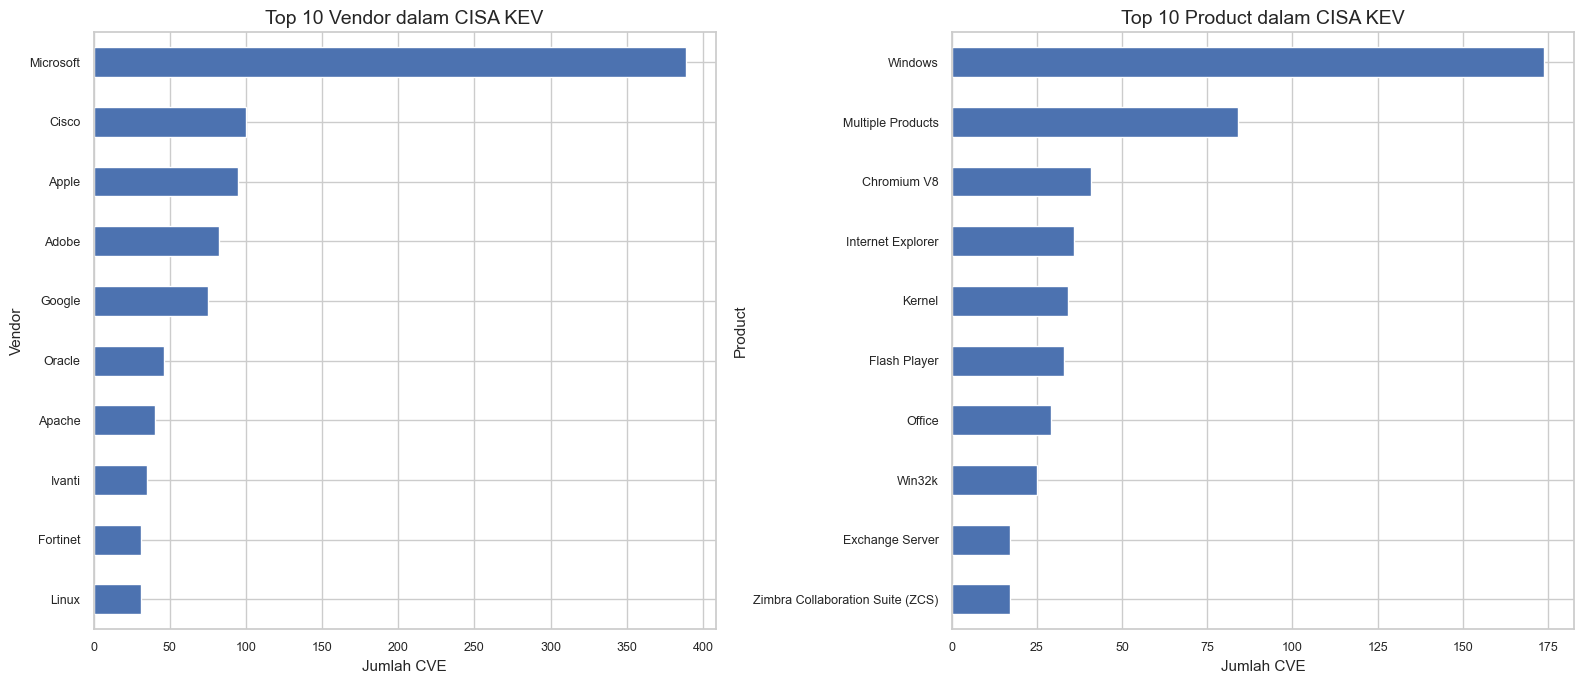

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

q1_vendor.plot(kind="barh", ax=axes[0])
axes[0].set_title("Top 10 Vendor dalam CISA KEV")
axes[0].set_xlabel("Jumlah CVE")
axes[0].set_ylabel("Vendor")

q1_product.plot(kind="barh", ax=axes[1])
axes[1].set_title("Top 10 Product dalam CISA KEV")
axes[1].set_xlabel("Jumlah CVE")
axes[1].set_ylabel("Product")

plt.tight_layout()
plt.show()

### Interpretasi Q1

Gunakan tabel dan bar chart di atas untuk menyebutkan vendor dan produk yang paling dominan. Q1 bersifat deskriptif: hasil ini menunjukkan **komposisi katalog KEV**, bukan peluang bahwa suatu vendor atau produk pasti akan dieksploitasi.

## 5.2 EDA Q2 — CVSS dan EPSS

**Pertanyaan:** Bagaimana karakteristik sebaran tingkat keparahan teknis (NVD) dibandingkan dengan probabilitas ancaman nyata (EPSS) pada celah keamanan tersebut?

In [29]:
q2 = df_analysis[["cvssScore", "epssScore"]].dropna().copy()

spearman_rho, spearman_p = stats.spearmanr(q2["cvssScore"], q2["epssScore"])
pearson_r, pearson_p = stats.pearsonr(q2["cvssScore"], q2["epssScore"])

print(f"Observasi lengkap Q2 : {len(q2):,}")
print(f"Pearson r            : {pearson_r:.4f} (p={pearson_p:.4g})")
print(f"Spearman rho         : {spearman_rho:.4f} (p={spearman_p:.4g})")
print("\nStatistik CVSS:")
display(q2["cvssScore"].describe().to_frame())
print("Statistik EPSS:")
display(q2["epssScore"].describe().to_frame())

Observasi lengkap Q2 : 1,733
Pearson r            : 0.3372 (p=2.449e-47)
Spearman rho         : 0.3680 (p=1.041e-56)

Statistik CVSS:


,cvssScore
count,1733.000000
mean,8.396653
std,1.364127
min,1.900000
25%,7.800000
50%,8.800000
75%,9.800000
max,10.000000


Statistik EPSS:


,epssScore
count,1733.000000
mean,0.502655
std,0.387708
min,0.002330
25%,0.090110
50%,0.489860
75%,0.916970
max,0.999990


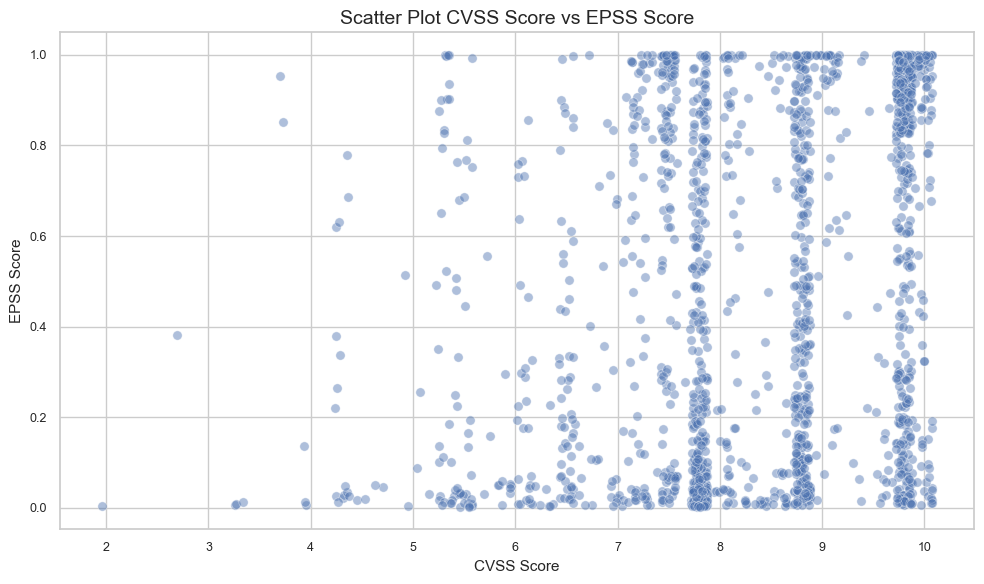

In [66]:
plt.figure(figsize=(10, 6))

# Tambahkan sedikit jitter pada CVSS agar titik yang menumpuk lebih terlihat
rng = np.random.default_rng(42)
x = q2["cvssScore"] + rng.uniform(-0.08, 0.08, len(q2))

sns.scatterplot(
    x=x,
    y=q2["epssScore"],
    alpha=0.45,
    s=45
)

plt.title("Scatter Plot CVSS Score vs EPSS Score")
plt.xlabel("CVSS Score")
plt.ylabel("EPSS Score")
plt.tight_layout()
plt.show()


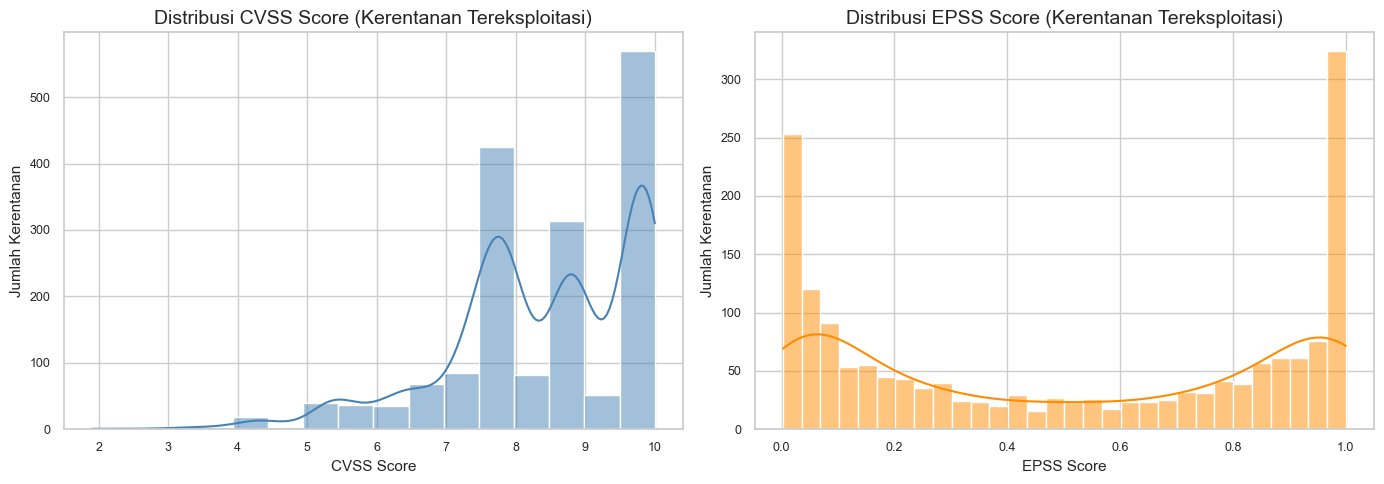

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(q2["cvssScore"], binwidth=0.5, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Distribusi CVSS Score (Kerentanan Tereksploitasi)")
axes[0].set_xlabel("CVSS Score")
axes[0].set_ylabel("Jumlah Kerentanan")

sns.histplot(q2["epssScore"], bins=30, kde=True, ax=axes[1], color="darkorange", kde_kws={'clip': (0.0, 1.0)})
axes[1].set_title("Distribusi EPSS Score (Kerentanan Tereksploitasi)")
axes[1].set_xlabel("EPSS Score")
axes[1].set_ylabel("Jumlah Kerentanan")

plt.tight_layout()
plt.show()


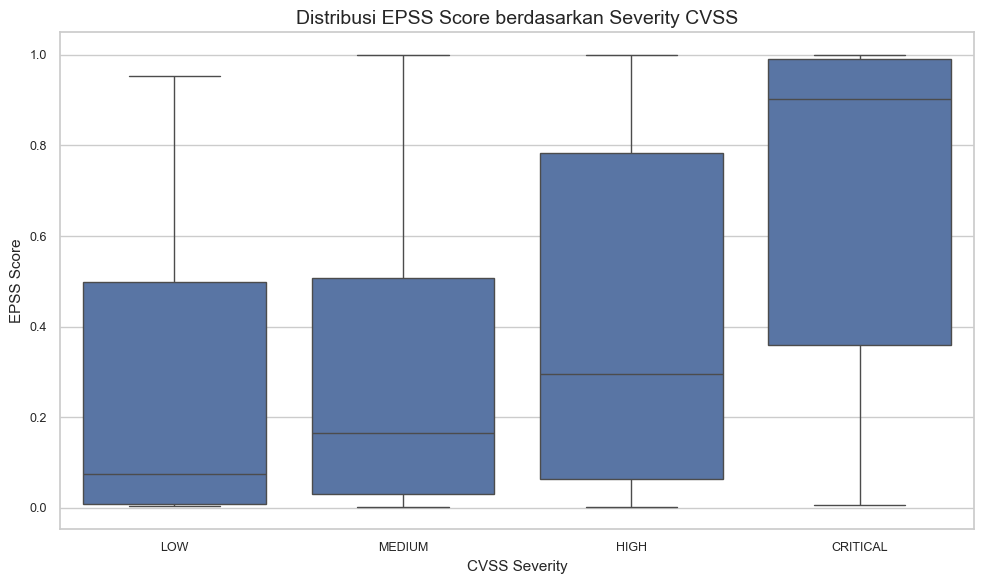

In [72]:
plt.figure(figsize=(10, 6))

q2_plot = q2.copy()

# Membentuk severity berdasarkan CVSS Score
q2_plot["severity"] = pd.cut(
    q2_plot["cvssScore"],
    bins=[-0.01, 3.9, 6.9, 8.9, 10.0],
    labels=["LOW", "MEDIUM", "HIGH", "CRITICAL"]
)

sns.boxplot(
    data=q2_plot,
    x="severity",
    y="epssScore",
    order=["LOW", "MEDIUM", "HIGH", "CRITICAL"]
)

plt.title("Distribusi EPSS Score berdasarkan Severity CVSS")
plt.xlabel("CVSS Severity")
plt.ylabel("EPSS Score")

plt.tight_layout()
plt.show()

### Interpretasi Q2

Perhatikan apakah hubungan CVSS–EPSS kuat atau lemah, serta apakah severity yang lebih tinggi selalu memiliki EPSS lebih tinggi. Hubungan yang tidak sempurna penting karena CVSS dan EPSS mengukur aspek risiko yang berbeda.

## 5.3 EDA Q3 — Attack Vector dan User Interaction

**Pertanyaan:** Seberapa besar ketergantungan para peretas pada interaksi pengguna (`userInteraction`) saat mengeksploitasi celah keamanan dengan jalur serangan yang berbeda (`attackVector`)?

In [33]:
q3 = df_analysis[["attackVector", "userInteraction"]].dropna().copy()
q3["attackVector"] = q3["attackVector"].astype(str).str.upper()
q3["userInteraction"] = q3["userInteraction"].astype(str).str.upper()

print(f"Baris yang dipakai: {len(q3):,} dari {len(df_analysis):,} CVE")
assert len(q3) == len(df_analysis), "dropna() membuang baris; periksa cleaning (NONE bukan missing)."

q3_crosstab = pd.crosstab(q3["attackVector"], q3["userInteraction"])
q3_row_pct = pd.crosstab(
    q3["attackVector"], q3["userInteraction"], normalize="index"
) * 100

print("Jumlah CVE per kombinasi:")
display(q3_crosstab)
print("Persentase di dalam masing-masing Attack Vector:")
display(q3_row_pct.round(2))

Baris yang dipakai: 1,733 dari 1,733 CVE
Jumlah CVE per kombinasi:


userInteraction,NONE,REQUIRED
attackVector,,
ADJACENT_NETWORK,28,2
LOCAL,266,151
NETWORK,987,292
PHYSICAL,7,0


Persentase di dalam masing-masing Attack Vector:


userInteraction,NONE,REQUIRED
attackVector,,
ADJACENT_NETWORK,93.33,6.67
LOCAL,63.79,36.21
NETWORK,77.17,22.83
PHYSICAL,100.00,0.00


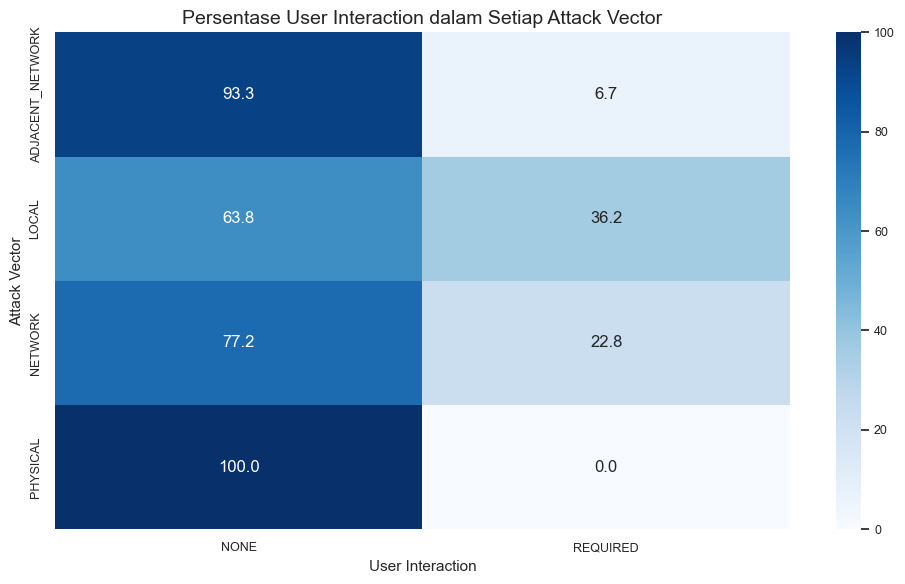

In [34]:
plt.figure(figsize=(10, 6))
sns.heatmap(q3_row_pct, annot=True, fmt=".1f", cmap="Blues")
plt.title("Persentase User Interaction dalam Setiap Attack Vector")
plt.xlabel("User Interaction")
plt.ylabel("Attack Vector")
plt.tight_layout()
plt.show()

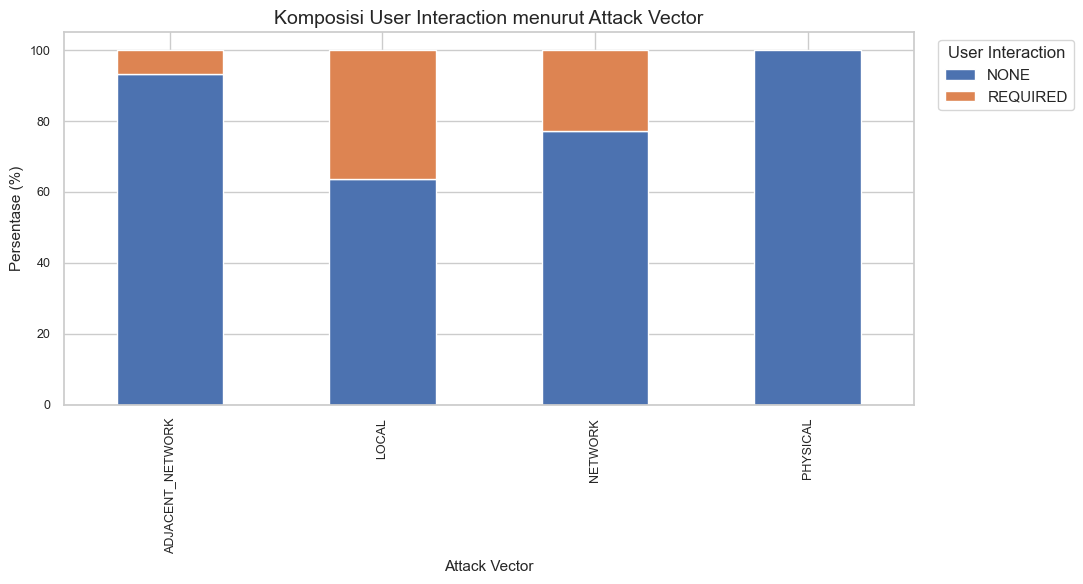

In [35]:
q3_plot = q3_crosstab.div(q3_crosstab.sum(axis=1), axis=0) * 100
q3_plot.plot(kind="bar", stacked=True, figsize=(11, 6))
plt.title("Komposisi User Interaction menurut Attack Vector")
plt.xlabel("Attack Vector")
plt.ylabel("Persentase (%)")
plt.legend(title="User Interaction", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Interpretasi Q3

Fokuskan penjelasan pada kombinasi yang paling dominan, misalnya apakah `NETWORK` lebih banyak memiliki `NONE` atau `REQUIRED`. Hindari menggeneralisasi hasil ini menjadi perilaku semua hacker; hasil hanya menggambarkan vulnerability yang tercatat di KEV.

## 5.4 EDA Q4 — Apakah Populasi KEV Memiliki Profil yang Berbeda?

**Pertanyaan:** Apakah vulnerability yang telah masuk CISA KEV menunjukkan profil karakteristik yang berbeda berdasarkan tingkat keparahan, probabilitas eksploitasi, karakteristik serangan, dan dampaknya?

Di sini kita **belum melakukan clustering**. Tujuannya adalah mencari bukti eksploratif bahwa data tidak homogen: terdapat variasi CVSS/EPSS, kombinasi teknis yang beragam, serta variasi dampak.

In [36]:
Q4_RAW_FEATURES = [
    "cvssScore",
    "epssScore",
    "attackVector",
    "attackComplexity",
    "privilegesRequired",
    "userInteraction",
    "confidentialityImpact",
    "integrityImpact",
    "availabilityImpact",
    "knownRansomwareCampaignUse",
]

available_q4 = [c for c in Q4_RAW_FEATURES if c in df_analysis.columns]
missing_q4 = [c for c in Q4_RAW_FEATURES if c not in df_analysis.columns]

print("10 variabel Q4:")
print(available_q4)
if missing_q4:
    print("Kolom yang tidak ditemukan:", missing_q4)

10 variabel Q4:
['cvssScore', 'epssScore', 'attackVector', 'attackComplexity', 'privilegesRequired', 'userInteraction', 'confidentialityImpact', 'integrityImpact', 'availabilityImpact', 'knownRansomwareCampaignUse']


### A. Variasi CVSS dan EPSS

Variasi yang lebar pada CVSS/EPSS merupakan indikasi awal bahwa populasi KEV tidak sepenuhnya homogen dalam risiko teknis dan probabilitas eksploitasi.

In [37]:
q4_numeric = df_analysis[["cvssScore", "epssScore"]].describe(percentiles=[0.25, 0.5, 0.75]).T
q4_numeric["IQR"] = q4_numeric["75%"] - q4_numeric["25%"]
display(q4_numeric[["count", "mean", "std", "min", "25%", "50%", "75%", "max", "IQR"]])

,count,mean,std,min,25%,50%,75%,max,IQR
cvssScore,1733.0,8.396653,1.364127,1.90000,7.80000,8.80000,9.80000,10.00000,2.00000
epssScore,1733.0,0.502655,0.387708,0.00233,0.09011,0.48986,0.91697,0.99999,0.82686


### B. Keragaman kombinasi karakteristik serangan

Empat variabel ini menjelaskan kondisi teknis eksploitasi. Kita hitung berapa banyak kombinasi yang benar-benar muncul di data dan kombinasi mana yang paling sering.

In [38]:
attack_features = [
    "attackVector", "attackComplexity", "privilegesRequired", "userInteraction"
]
q4_attack = df_analysis[attack_features].dropna().copy().astype(str)
q4_attack["attack_profile"] = q4_attack.astype(str).agg(" | ".join, axis=1)

print(f"Baris yang dipakai: {len(q4_attack):,} dari {len(df_analysis):,} CVE")
assert len(q4_attack) == len(df_analysis), "dropna() membuang baris; periksa cleaning (NONE bukan missing)."
print(f"Jumlah kombinasi attack profile yang muncul: {q4_attack['attack_profile'].nunique():,}")
print("Top 10 kombinasi:")
display(q4_attack["attack_profile"].value_counts().head(10).to_frame("jumlah_CVE"))

Baris yang dipakai: 1,733 dari 1,733 CVE
Jumlah kombinasi attack profile yang muncul: 32
Top 10 kombinasi:


,jumlah_CVE
attack_profile,
NETWORK | LOW | NONE | NONE,731
NETWORK | LOW | NONE | REQUIRED,252
LOCAL | LOW | LOW | NONE,212
LOCAL | LOW | NONE | REQUIRED,140
NETWORK | LOW | LOW | NONE,127
NETWORK | HIGH | NONE | NONE,61
NETWORK | LOW | HIGH | NONE,52
NETWORK | HIGH | NONE | REQUIRED,24
LOCAL | LOW | NONE | NONE,22


### C. Variasi dampak

Tiga impact metric dibandingkan untuk melihat apakah vulnerability yang masuk KEV mempunyai pola dampak yang seragam atau beragam.

In [39]:
impact_features = ["confidentialityImpact", "integrityImpact", "availabilityImpact"]
q4_impact = df_analysis[impact_features].dropna().copy().astype(str)
q4_impact["impact_profile"] = q4_impact.astype(str).agg(" | ".join, axis=1)

print(f"Baris yang dipakai: {len(q4_impact):,} dari {len(df_analysis):,} CVE")
assert len(q4_impact) == len(df_analysis), "dropna() membuang baris; periksa cleaning (NONE bukan missing)."
print(f"Jumlah kombinasi impact profile yang muncul: {q4_impact['impact_profile'].nunique():,}")
display(q4_impact["impact_profile"].value_counts().head(10).to_frame("jumlah_CVE"))

Baris yang dipakai: 1,733 dari 1,733 CVE
Jumlah kombinasi impact profile yang muncul: 25


,jumlah_CVE
impact_profile,
HIGH | HIGH | HIGH,1339
HIGH | NONE | NONE,123
NONE | NONE | HIGH,51
HIGH | HIGH | NONE,44
LOW | LOW | NONE,44
LOW | NONE | NONE,25
NONE | HIGH | NONE,22
NONE | LOW | NONE,15
HIGH | LOW | NONE,12


### D. Pola multidimensi: Attack Vector × Privileges Required terhadap EPSS

Visual ini melihat lebih dari dua variabel sekaligus. Warna menunjukkan median EPSS pada setiap kombinasi kategori.

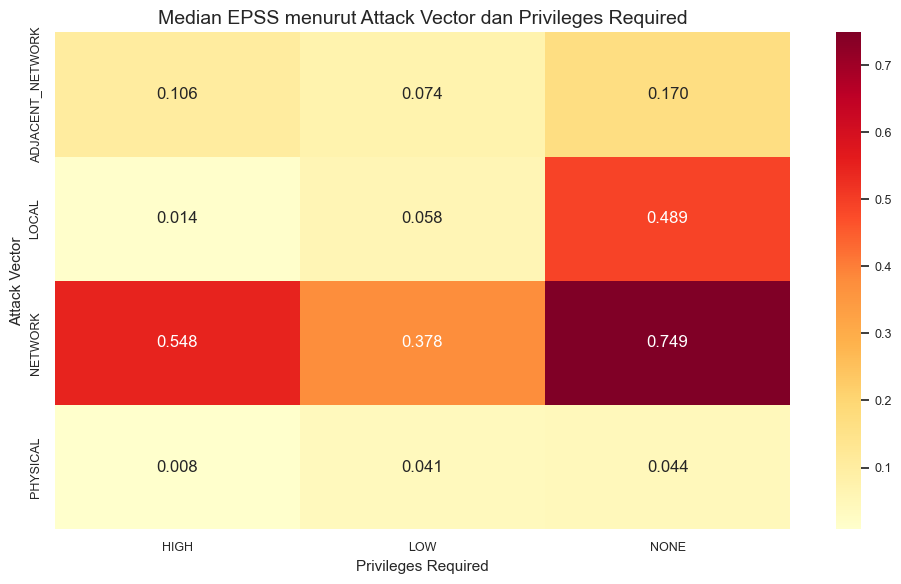

In [40]:
q4_heat = df_analysis[["attackVector", "privilegesRequired", "epssScore"]].dropna().copy()
q4_heat["attackVector"] = q4_heat["attackVector"].astype(str).str.upper()
q4_heat["privilegesRequired"] = q4_heat["privilegesRequired"].astype(str).str.upper()
q4_heatmap = q4_heat.pivot_table(
    index="attackVector",
    columns="privilegesRequired",
    values="epssScore",
    aggfunc="median"
)

plt.figure(figsize=(10, 6))
sns.heatmap(q4_heatmap, annot=True, fmt=".3f", cmap="YlOrRd")
plt.title("Median EPSS menurut Attack Vector dan Privileges Required")
plt.xlabel("Privileges Required")
plt.ylabel("Attack Vector")
plt.tight_layout()
plt.show()

### E. Pola teknis dan dampak vs CVSS/EPSS

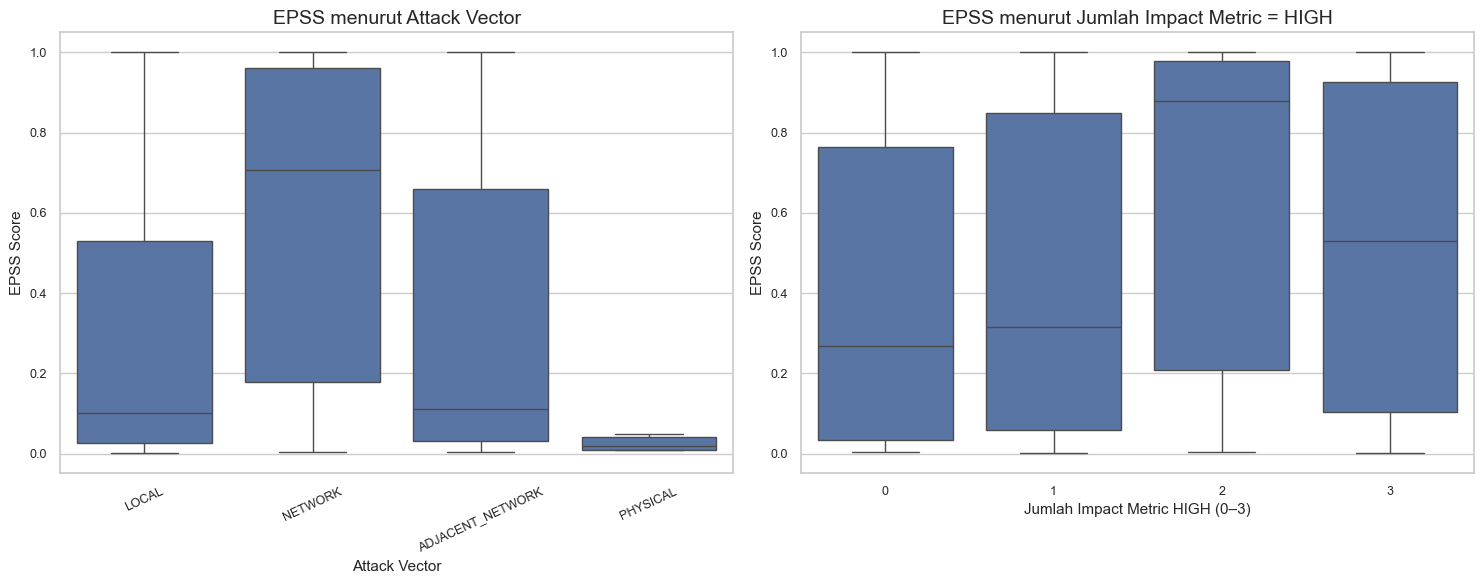

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

if "attackVector" in df_analysis.columns:
    sns.boxplot(data=df_analysis, x="attackVector", y="epssScore", ax=axes[0])
    axes[0].set_title("EPSS menurut Attack Vector")
    axes[0].set_xlabel("Attack Vector")
    axes[0].set_ylabel("EPSS Score")
    axes[0].tick_params(axis="x", rotation=25)

impact_count = df_analysis[["confidentialityImpact", "integrityImpact", "availabilityImpact"]].copy()
impact_count = impact_count.astype("string").eq("HIGH").sum(axis=1)
impact_plot = pd.DataFrame({"high_impact_count": impact_count, "epssScore": df_analysis["epssScore"]}).dropna()
sns.boxplot(data=impact_plot, x="high_impact_count", y="epssScore", ax=axes[1])
axes[1].set_title("EPSS menurut Jumlah Impact Metric = HIGH")
axes[1].set_xlabel("Jumlah Impact Metric HIGH (0–3)")
axes[1].set_ylabel("EPSS Score")

plt.tight_layout()
plt.show()

### Kesimpulan EDA Q4 — sebelum ML

Dari EDA Q4, simpulkan apakah:

- CVSS dan EPSS mempunyai rentang yang cukup beragam;
- kombinasi karakteristik serangan tidak hanya terdiri dari satu pola;
- impact profile juga bervariasi;
- terdapat perbedaan nilai EPSS antar kombinasi karakteristik teknis.

**Jika pola-pola tersebut terlihat, maka clustering layak dicoba sebagai tahap Model AI.** EDA tidak menetapkan jumlah cluster. Jumlah cluster ditentukan kemudian melalui evaluasi K-Means.

# 6. Visualization & Explanatory Analysis

Bagian ini memilih ulang visual utama yang paling mudah dipahami untuk presentasi/laporan. Data dan perhitungan berasal dari EDA sebelumnya; bagian ini tidak membuat pertanyaan baru.

## Visual Utama Q1 — Top Vendor dan Product

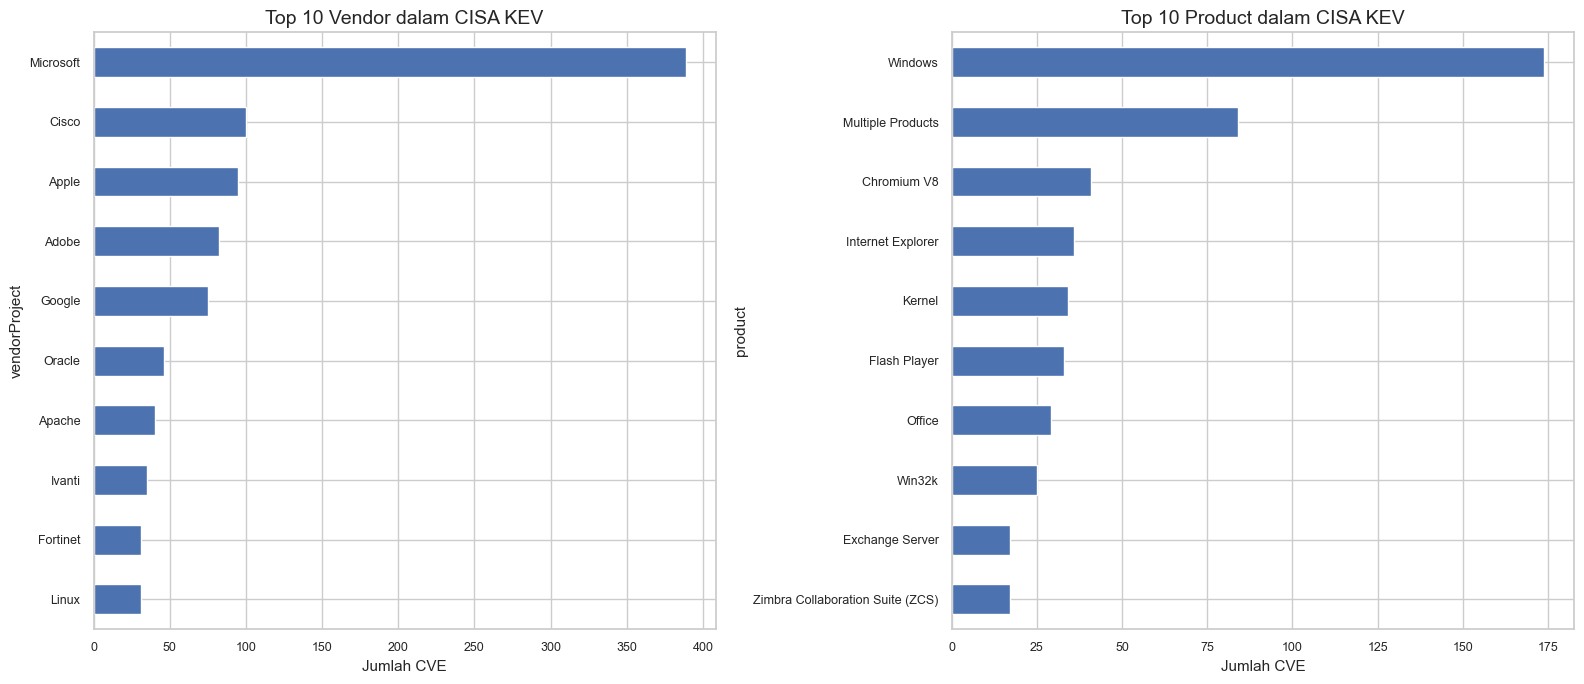

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
q1_vendor.sort_values().plot(kind="barh", ax=axes[0])
axes[0].set_title("Top 10 Vendor dalam CISA KEV")
axes[0].set_xlabel("Jumlah CVE")
q1_product.sort_values().plot(kind="barh", ax=axes[1])
axes[1].set_title("Top 10 Product dalam CISA KEV")
axes[1].set_xlabel("Jumlah CVE")
plt.tight_layout()
plt.show()

## Visual Utama Q2 — CVSS vs EPSS

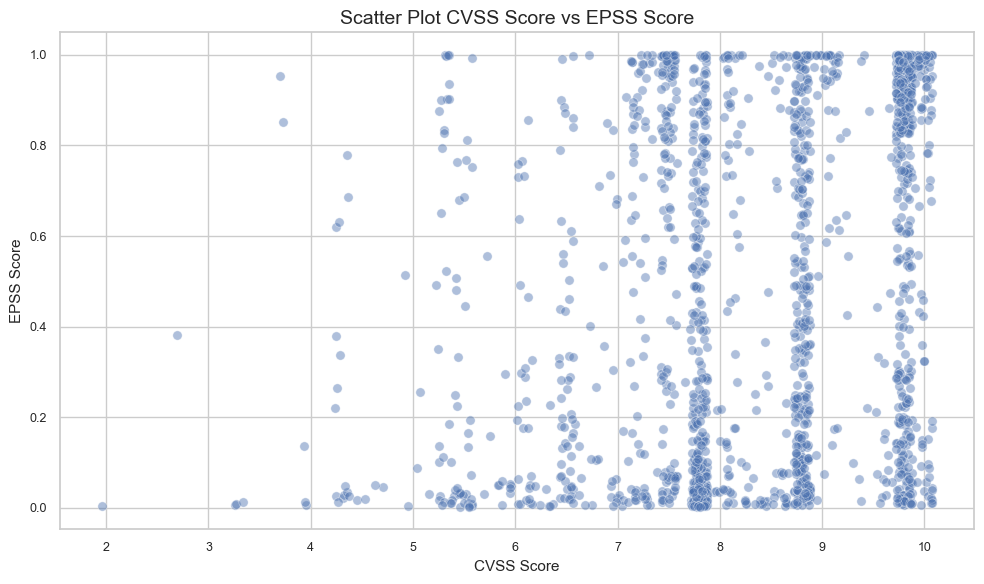

In [73]:
plt.figure(figsize=(10, 6))

# Tambahkan sedikit jitter pada CVSS agar titik yang menumpuk lebih terlihat
rng = np.random.default_rng(42)
x = q2["cvssScore"] + rng.uniform(-0.08, 0.08, len(q2))

sns.scatterplot(
    x=x,
    y=q2["epssScore"],
    alpha=0.45,
    s=45
)

plt.title("Scatter Plot CVSS Score vs EPSS Score")
plt.xlabel("CVSS Score")
plt.ylabel("EPSS Score")
plt.tight_layout()
plt.show()


## Visual Utama Q3 — Attack Vector × User Interaction

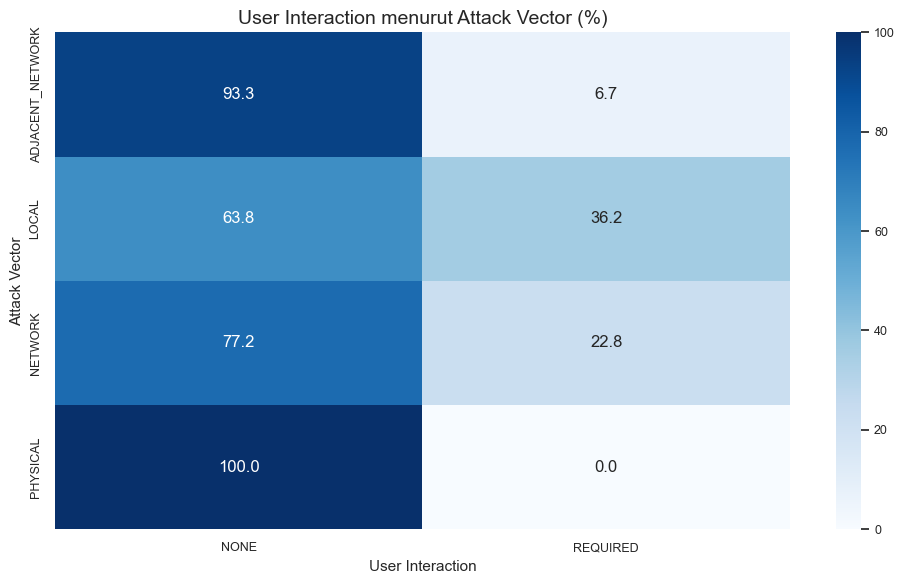

In [44]:
plt.figure(figsize=(10, 6))
sns.heatmap(q3_row_pct, annot=True, fmt=".1f", cmap="Blues")
plt.title("User Interaction menurut Attack Vector (%)")
plt.xlabel("User Interaction")
plt.ylabel("Attack Vector")
plt.tight_layout()
plt.show()

## Visual Utama Q4 — Bukti Heterogenitas

Sebelum clustering, scatter CVSS–EPSS membantu menunjukkan apakah observasi tersebar pada banyak kombinasi risiko.

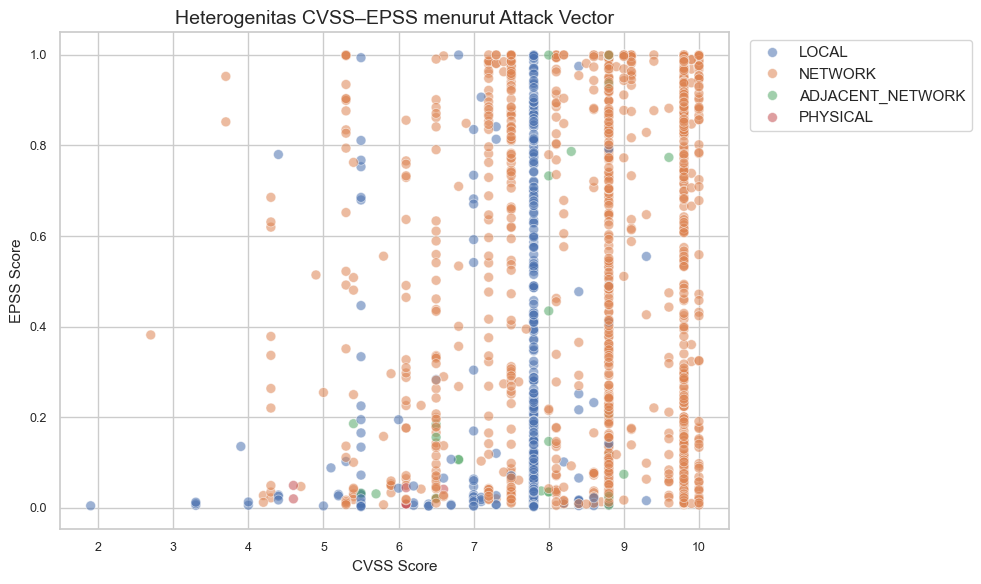

In [45]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_analysis,
    x="cvssScore",
    y="epssScore",
    hue="attackVector",
    alpha=0.55,
    s=50,
)
plt.title("Heterogenitas CVSS–EPSS menurut Attack Vector")
plt.xlabel("CVSS Score")
plt.ylabel("EPSS Score")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# 7. Analisis Lanjutan (Opsional)

Analisis ini dilakukan setelah EDA utama dan sebelum kesimpulan EDA. Tujuannya memperkaya cerita tanpa mengubah empat pertanyaan utama.

## 7.1 Remediation Window

`dueDate - dateAdded` dipakai sebagai **rentang waktu operasional yang diberikan CISA untuk remediasi**, bukan waktu menuju eksploitasi.

,remediationWindowDays
count,1733.000000
mean,41.993076
std,58.326468
min,1.000000
25%,14.000000
50%,21.000000
75%,21.000000
max,184.000000


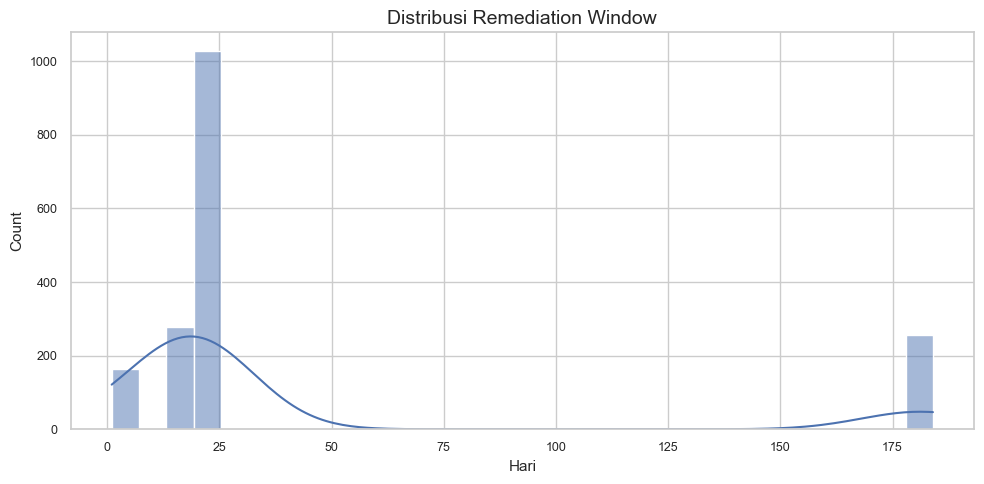

In [46]:
if {"dateAdded", "dueDate"}.issubset(df_analysis.columns):
    temp_window = df_analysis[["dateAdded", "dueDate"]].copy()
    temp_window["remediationWindowDays"] = (
        temp_window["dueDate"] - temp_window["dateAdded"]
    ).dt.days
    display(temp_window["remediationWindowDays"].describe().to_frame())
    plt.figure(figsize=(10, 5))
    sns.histplot(temp_window["remediationWindowDays"].dropna(), bins=30, kde=True)
    plt.title("Distribusi Remediation Window")
    plt.xlabel("Hari")
    plt.tight_layout()
    plt.show()
else:
    print("Kolom tanggal tidak lengkap untuk analisis remediation window.")

# 8. Conclusion

Kesimpulan di bagian ini merangkum **hasil EDA Q1–Q4**. Hasil cluster dari Model AI dibahas pada bagian berikutnya, karena sesuai urutan tugas model dibuat setelah kesimpulan EDA.

## Jawaban Q1

**Vendor dan produk dominan:** gunakan output Top 10 Vendor dan Top 10 Product dari EDA Q1 untuk menyebutkan kelompok yang paling sering muncul dalam CISA KEV.

**Inti makna:** Q1 memberikan gambaran target teknologi yang paling sering muncul dalam katalog vulnerability yang telah diketahui tereksploitasi.

## Jawaban Q2

**Hubungan CVSS dan EPSS:** CVSS dan EPSS pada CVE di KEV bergerak searah, tetapi hubungannya lemah hingga sedang (Pearson r = 0,337; Spearman ρ = 0,368; p < 0,001; n = 1.733). Sebaran CVSS condong ke nilai tinggi (rata-rata 8,40; median 8,8) dan menumpuk pada skor 7,8; 8,8; dan 9,8. EPSS tersebar sangat lebar dan berbentuk U (rata-rata 0,50; simpangan baku 0,39), dengan sebagian besar CVE berada di dekat 0 atau di dekat 1. Median EPSS naik seiring severity (LOW ≈ 0,07; MEDIUM ≈ 0,17; HIGH ≈ 0,30; CRITICAL ≈ 0,90), tetapi rentang antar-kategori saling tumpang tindih. Ada CVE CRITICAL dengan EPSS sangat rendah dan CVE severity rendah dengan EPSS tinggi.

**Inti makna:** CVSS dan EPSS tidak memberikan urutan risiko yang sama, sehingga keduanya memberi perspektif yang berbeda terhadap vulnerability KEV. CVSS mengukur tingkat keparahan teknis, sedangkan EPSS mengukur probabilitas eksploitasi 30 hari ke depan. Skor CVSS tinggi tidak otomatis berarti EPSS tinggi, sehingga prioritas penanganan sebaiknya mempertimbangkan keduanya. EPSS adalah estimasi probabilitas, bukan bukti eksploitasi. Bukti eksploitasi dalam penelitian ini berasal dari keanggotaan CVE di KEV.

## Jawaban Q3

**Attack Vector × User Interaction:** gunakan tabel silang dan persentase per Attack Vector untuk menjelaskan pola `NONE` dan `REQUIRED` pada masing-masing jalur serangan.

**Inti makna:** hasil menggambarkan pola karakteristik vulnerability yang sudah tercatat di KEV, bukan perilaku semua hacker secara umum.

## Jawaban Q4

**Hasil EDA Q4:** gunakan variasi CVSS, EPSS, kombinasi karakteristik serangan, impact profile, dan heatmap multidimensi untuk menjelaskan apakah populasi KEV bersifat heterogen.

**Implikasi untuk Model AI:** apabila terdapat pola yang beragam, tahap berikutnya layak menggunakan **K-Means Clustering** untuk menemukan kelompok vulnerability yang memiliki karakteristik mirip secara otomatis.

# 9. Model AI — Feature Engineering + K-Means Clustering

## Hubungan dengan Q4

Q4 sudah terlebih dahulu dieksplorasi pada EDA. Karena EDA menunjukkan adanya variasi pada severity, probabilitas eksploitasi, karakteristik serangan, dan impact, kita lanjutkan dengan **unsupervised learning** untuk menemukan profil vulnerability.

Model tidak memprediksi apakah vulnerability akan dieksploitasi. Semua observasi sudah berasal dari CISA KEV.

## 9.1 Feature Selection — 10 variabel Q4

Sepuluh variabel berikut adalah **candidate raw features** yang memang dipakai untuk membangun representasi model:

### NVD
1. `cvssScore`
2. `attackVector`
3. `attackComplexity`
4. `privilegesRequired`
5. `userInteraction`
6. `confidentialityImpact`
7. `integrityImpact`
8. `availabilityImpact`

### EPSS
9. `epssScore`

### KEV
10. `knownRansomwareCampaignUse`

Variabel identitas seperti `cveID`, vendor/product, dan kolom teks panjang tidak dimasukkan ke pembentukan cluster. Variabel tersebut tetap tersedia untuk profiling hasil cluster.

### Kolom bantu (bukan variabel Q4)
`scope` dari NVD tidak termasuk 10 variabel Q4, tetapi **dibutuhkan** untuk menghitung sub-skor resmi CVSS: bobot `privilegesRequired` dan rumus impact berbeda ketika scope = `CHANGED`. Karena itu `scope` ikut dibawa ke tahap feature engineering, dan dipakai kembali sebagai variabel profiling.

In [47]:
ML_RAW_FEATURES = [
    "cvssScore",
    "epssScore",
    "attackVector",
    "attackComplexity",
    "privilegesRequired",
    "userInteraction",
    "confidentialityImpact",
    "integrityImpact",
    "availabilityImpact",
    "knownRansomwareCampaignUse",
]

missing_ml_features = [c for c in ML_RAW_FEATURES if c not in df_analysis.columns]
if missing_ml_features:
    raise ValueError(f"Fitur ML tidak ditemukan: {missing_ml_features}")

print(f"Jumlah raw features untuk Q4: {len(ML_RAW_FEATURES)}")
print(ML_RAW_FEATURES)

Jumlah raw features untuk Q4: 10
['cvssScore', 'epssScore', 'attackVector', 'attackComplexity', 'privilegesRequired', 'userInteraction', 'confidentialityImpact', 'integrityImpact', 'availabilityImpact', 'knownRansomwareCampaignUse']


## 9.2 Menyiapkan data model

K-Means membutuhkan input numerik tanpa missing value. Setelah cleaning diperbaiki, **kolom kategori CVSS tidak memiliki missing** (`NONE` adalah nilai sah). Konsekuensinya:

- **tidak ada imputasi kategori** dan **tidak ada baris yang dibuang**: seluruh CVE KEV masuk ke model;
- jika masih ada missing pada kolom kategori, notebook **berhenti** dan meminta pemeriksaan data. Kategori CVSS tidak boleh diisi modus, karena pengisian modus itulah yang sebelumnya mengubah `NONE` menjadi `REQUIRED` / `LOW` / `HIGH`;
- imputasi median untuk `cvssScore` dan `epssScore` tetap dipertahankan sebagai pengaman, tetapi jumlah yang diimputasi diharapkan **0**.

`knownRansomwareCampaignUse` tetap dipertahankan sebagai variabel konteks untuk profiling setelah cluster terbentuk, sehingga tidak mengurangi populasi model.

In [48]:
ML_MODEL_RAW_FEATURES = [
    "cvssScore",
    "epssScore",
    "attackVector",
    "attackComplexity",
    "privilegesRequired",
    "userInteraction",
    "confidentialityImpact",
    "integrityImpact",
    "availabilityImpact",
]

# scope = kolom bantu untuk rumus resmi sub-skor CVSS (lihat 9.1)
df_model_raw = df_analysis[["cveID"] + ML_RAW_FEATURES + ["scope"]].copy()

print(f"Baris awal untuk model: {len(df_model_raw):,}")

# Normalisasi kolom kategorikal sebelum validasi/mapping.
categorical_raw = [
    "attackVector",
    "attackComplexity",
    "privilegesRequired",
    "userInteraction",
    "confidentialityImpact",
    "integrityImpact",
    "availabilityImpact",
    "scope",
]

for col in categorical_raw:
    df_model_raw[col] = (
        df_model_raw[col]
        .astype("string")
        .str.strip()
        .str.upper()
        .replace({"": pd.NA, "NAN": pd.NA})   # 'NONE' sengaja TIDAK dimasukkan: itu nilai sah CVSS
    )

# Nilai numerik dipastikan numeric.
for col in ["cvssScore", "epssScore"]:
    df_model_raw[col] = pd.to_numeric(df_model_raw[col], errors="coerce")

# Laporkan missing sebelum imputasi.
missing_before_imputation = (
    df_model_raw[ML_MODEL_RAW_FEATURES + ["scope"]].isna().sum().sort_values(ascending=False)
)
display(missing_before_imputation.to_frame("missing_sebelum_imputasi"))

# Kategori CVSS seharusnya lengkap. Jika tidak, hentikan dan periksa; JANGAN diisi modus.
kategori_missing = df_model_raw[categorical_raw].isna().sum()
assert kategori_missing.sum() == 0, (
    "Ada kategori CVSS yang benar-benar kosong:\n"
    f"{kategori_missing[kategori_missing > 0]}\n"
    "Periksa tahap cleaning; jangan diimputasi dengan modus."
)

# Imputasi median hanya sebagai pengaman untuk numerik.
for col in ["cvssScore", "epssScore"]:
    n_missing = int(df_model_raw[col].isna().sum())
    median_value = df_model_raw[col].median()
    if pd.isna(median_value):
        raise ValueError(f"Kolom numerik {col} seluruhnya missing; data tidak cukup untuk feature engineering.")
    df_model_raw[col] = df_model_raw[col].fillna(median_value)
    print(f"{col}: {n_missing} nilai diimputasi median")

# Verifikasi: tidak ada baris yang hilang, dan NONE masih ada.
assert len(df_model_raw) == len(df_analysis), "Jumlah baris model berbeda dari df_analysis."
print(f"\nBaris untuk model       : {len(df_model_raw):,}")
print(f"CVE yang dipertahankan  : {df_model_raw['cveID'].nunique():,}")

print("\nuserInteraction:")
display(df_model_raw["userInteraction"].value_counts().to_frame("jumlah"))
print("privilegesRequired:")
display(df_model_raw["privilegesRequired"].value_counts().to_frame("jumlah"))

Baris awal untuk model: 1,733


,missing_sebelum_imputasi
cvssScore,0
epssScore,0
attackVector,0
attackComplexity,0
privilegesRequired,0
userInteraction,0
confidentialityImpact,0
integrityImpact,0
availabilityImpact,0
scope,0


cvssScore: 0 nilai diimputasi median
epssScore: 0 nilai diimputasi median

Baris untuk model       : 1,733
CVE yang dipertahankan  : 1,733

userInteraction:


,jumlah
userInteraction,
NONE,1288
REQUIRED,445


privilegesRequired:


,jumlah
privilegesRequired,
NONE,1254
LOW,395
HIGH,84


## 9.3 Feature Engineering

Kita tidak memasukkan 10 raw columns langsung ke K-Means. Variabel yang membahas konsep yang sama diringkas menjadi fitur numerik yang bisa diinterpretasikan.

### Input akhir K-Means

1. **`exploitabilityIndex`** → ringkasan karakteristik serangan dari `attackVector`, `attackComplexity`, `privilegesRequired`, `userInteraction` (dan `scope` untuk bobot privileges).
2. **`impactIndex`** → ringkasan dampak dari `confidentialityImpact`, `integrityImpact`, `availabilityImpact` (dan `scope`).
3. **`epssScore`** → probabilitas eksploitasi menurut EPSS.

`cvssScore` **tidak** menjadi input K-Means, tetapi tetap dipakai untuk **validasi dan profiling** (representasi tingkat keparahan). `knownRansomwareCampaignUse` juga tetap menjadi variabel konteks untuk profiling.

### Kenapa dua index memakai rumus resmi CVSS v3.x

- `exploitabilityIndex` = sub-skor *Exploitability* resmi: **8,22 × AV × AC × PR × UI**.
- `impactIndex` = sub-skor *Impact* resmi, dihitung dari ISS = 1 − (1−C)(1−I)(1−A), lalu 6,42 × ISS bila scope `UNCHANGED`, atau 7,52 × (ISS − 0,029) − 3,25 × (ISS − 0,02)^15 bila scope `CHANGED`.
- Bobot tiap kategori mengikuti spesifikasi CVSS v3.1 (FIRST). Nilai ini bukan skor baru dan bukan buatan sendiri, sehingga dapat diverifikasi: menghitung ulang *base score* dari kedua sub-skor harus menghasilkan `cvssScore` dari NVD.

### Apa yang salah pada versi sebelumnya

1. **Informasi dihitung tiga kali.** `cvssScore` adalah fungsi deterministik dari exploitability, impact, dan scope. Memasukkan `cvssScore` bersama dua index membuat sisi teknis berbobot 3 dari 4 fitur, sedangkan EPSS (satu-satunya informasi yang independen) hanya 1 dari 4.
2. **Rata-rata ordinal sembarang.** Rata-rata bobot sama (mis. `LOCAL` = 0,33) tidak sama dengan bobot CVSS, `scope` tidak ikut, dan rata-rata menghilangkan identitas kombinasi (nilai 0,625 bisa berasal dari banyak kombinasi berbeda).
3. **Input sudah rusak sebelum dihitung** karena `NONE` berubah menjadi missing lalu diisi modus (lihat 4.3).

**Catatan metodologis:** nama kolom `exploitabilityIndex` dan `impactIndex` dipertahankan agar alur notebook tetap sama, tetapi isinya sekarang sub-skor resmi CVSS (rentang kira-kira 0,12–3,89 dan 0–6,05), bukan rata-rata 0–1 seperti sebelumnya.

In [49]:
# Bobot resmi CVSS v3.x (FIRST, spesifikasi v3.1)
AV_WEIGHT = {"NETWORK": 0.85, "ADJACENT_NETWORK": 0.62, "ADJACENT": 0.62, "LOCAL": 0.55, "PHYSICAL": 0.20}
AC_WEIGHT = {"LOW": 0.77, "HIGH": 0.44}
UI_WEIGHT = {"NONE": 0.85, "REQUIRED": 0.62}
CIA_WEIGHT = {"HIGH": 0.56, "LOW": 0.22, "NONE": 0.00}
PR_WEIGHT_UNCHANGED = {"NONE": 0.85, "LOW": 0.62, "HIGH": 0.27}
PR_WEIGHT_CHANGED = {"NONE": 0.85, "LOW": 0.68, "HIGH": 0.50}


def map_weight(series, mapping, name):
    cleaned = series.astype("string").str.upper().str.strip()
    mapped = cleaned.map(mapping)
    unknown = sorted(set(cleaned[mapped.isna()].dropna().astype(str)))
    if unknown or mapped.isna().any():
        raise ValueError(f"Kategori {name} yang tidak dikenali: {unknown}")
    return mapped.astype(float).to_numpy()


def cvss_roundup(x):
    # Fungsi Roundup resmi CVSS v3.1 (pembulatan ke atas 1 desimal)
    i = int(round(x * 100000))
    return i / 100000.0 if i % 10000 == 0 else (i // 10000 + 1) / 10.0


df_fe = df_model_raw.copy()
scope_changed = df_fe["scope"].eq("CHANGED").to_numpy(dtype=bool)

# 4 variabel serangan -> exploitability sub-score
av = map_weight(df_fe["attackVector"], AV_WEIGHT, "attackVector")
ac = map_weight(df_fe["attackComplexity"], AC_WEIGHT, "attackComplexity")
ui = map_weight(df_fe["userInteraction"], UI_WEIGHT, "userInteraction")
pr = np.where(
    scope_changed,
    map_weight(df_fe["privilegesRequired"], PR_WEIGHT_CHANGED, "privilegesRequired"),
    map_weight(df_fe["privilegesRequired"], PR_WEIGHT_UNCHANGED, "privilegesRequired"),
)
exploitability = 8.22 * av * ac * pr * ui

# 3 variabel dampak -> impact sub-score
c = map_weight(df_fe["confidentialityImpact"], CIA_WEIGHT, "confidentialityImpact")
i_ = map_weight(df_fe["integrityImpact"], CIA_WEIGHT, "integrityImpact")
a = map_weight(df_fe["availabilityImpact"], CIA_WEIGHT, "availabilityImpact")
iss = 1 - (1 - c) * (1 - i_) * (1 - a)
impact_raw = np.where(
    scope_changed,
    7.52 * (iss - 0.029) - 3.25 * (iss - 0.02) ** 15,
    6.42 * iss,
)

df_fe["exploitabilityIndex"] = exploitability
df_fe["impactIndex"] = np.clip(impact_raw, 0, None)   # sub-skor impact <= 0 diperlakukan sebagai 0 (sesuai spesifikasi)

# Validasi 1: hitung ulang base score resmi dan bandingkan dengan cvssScore dari NVD.
combined = np.where(scope_changed, 1.08 * (impact_raw + exploitability), impact_raw + exploitability)
base_raw = np.where(impact_raw <= 0, 0.0, np.minimum(combined, 10.0))
df_fe["cvssRecomputed"] = [cvss_roundup(v) for v in base_raw]

match = np.isclose(df_fe["cvssRecomputed"], df_fe["cvssScore"], atol=0.05)
print(f"cvssScore NVD cocok dengan hitung ulang dari sub-skor: {match.mean():.1%} ({match.sum():,}/{len(match):,})")
if match.mean() < 0.90:
    print("PERINGATAN: kecocokan di bawah 90%. Periksa cleaning/mapping, atau kemungkinan sebagian CVE memakai versi CVSS lain.")
    display(df_fe.loc[~match, ["cveID", "cvssScore", "cvssRecomputed"]].head(10))

# Validasi 2: kombinasi NETWORK/LOW/NONE/NONE harus menghasilkan exploitability maksimum 3,887.
# Pada versi sebelumnya indeks maksimum hanya 0,625 karena NONE hilang saat cleaning.
assert np.isclose(df_fe["exploitabilityIndex"].max(), 3.887, atol=0.001), \
    f"exploitabilityIndex maksimum {df_fe['exploitabilityIndex'].max():.3f}, seharusnya 3.887. Periksa cleaning."

# knownRansomwareCampaignUse TIDAK menjadi input K-Means (dipakai untuk profiling).
# cvssScore TIDAK menjadi input K-Means (redundan dengan dua sub-skor; dipakai untuk validasi & profiling).
FINAL_MODEL_FEATURES = [
    "exploitabilityIndex",
    "impactIndex",
    "epssScore",
]

feature_na = df_fe[FINAL_MODEL_FEATURES].isna().sum()
print("\nMissing setelah feature engineering:")
display(feature_na.to_frame("missing_count"))

if feature_na.sum() > 0:
    raise ValueError("Masih ada missing pada fitur akhir K-Means.")

print(f"Fitur akhir K-Means ({len(FINAL_MODEL_FEATURES)}):")
print(FINAL_MODEL_FEATURES)
display(df_fe[["cveID", "cvssScore", "cvssRecomputed"] + FINAL_MODEL_FEATURES].head(10))

cvssScore NVD cocok dengan hitung ulang dari sub-skor: 100.0% (1,733/1,733)

Missing setelah feature engineering:


,missing_count
exploitabilityIndex,0
impactIndex,0
epssScore,0


Fitur akhir K-Means (3):
['exploitabilityIndex', 'impactIndex', 'epssScore']


,cveID,cvssScore,cvssRecomputed,exploitabilityIndex,impactIndex,epssScore
0,CVE-2002-0367,7.8,7.8,1.834577,5.873119,0.04919
1,CVE-2004-0210,7.8,7.8,1.834577,5.873119,0.07214
2,CVE-2004-1464,5.9,5.9,2.221167,3.595200,0.04840
3,CVE-2005-2773,9.8,9.8,3.887043,5.873119,0.74592
4,CVE-2006-1547,7.5,7.5,3.887043,3.595200,0.54635
5,CVE-2006-2492,8.8,8.8,2.835255,5.873119,0.48107
6,CVE-2007-0671,8.8,8.8,2.835255,5.873119,0.43241
7,CVE-2007-3010,9.8,9.8,3.887043,5.873119,0.97385
8,CVE-2007-5659,7.8,7.8,1.834577,5.873119,0.87423
9,CVE-2008-0015,8.8,8.8,2.835255,5.873119,0.76733


## 9.4 Memeriksa distribusi fitur hasil engineering

In [50]:
display(df_fe[["cvssScore"] + FINAL_MODEL_FEATURES].describe().T)

,count,mean,std,min,25%,50%,75%,max
cvssScore,1733.0,8.396653,1.364127,1.900000,7.800000,8.800000,9.800000,10.000000
exploitabilityIndex,1733.0,2.904766,0.960082,0.166011,1.834577,2.835255,3.887043,3.887043
impactIndex,1733.0,5.372088,1.103113,1.412400,5.873119,5.873119,5.873119,6.047730
epssScore,1733.0,0.502655,0.387708,0.002330,0.090110,0.489860,0.916970,0.999990


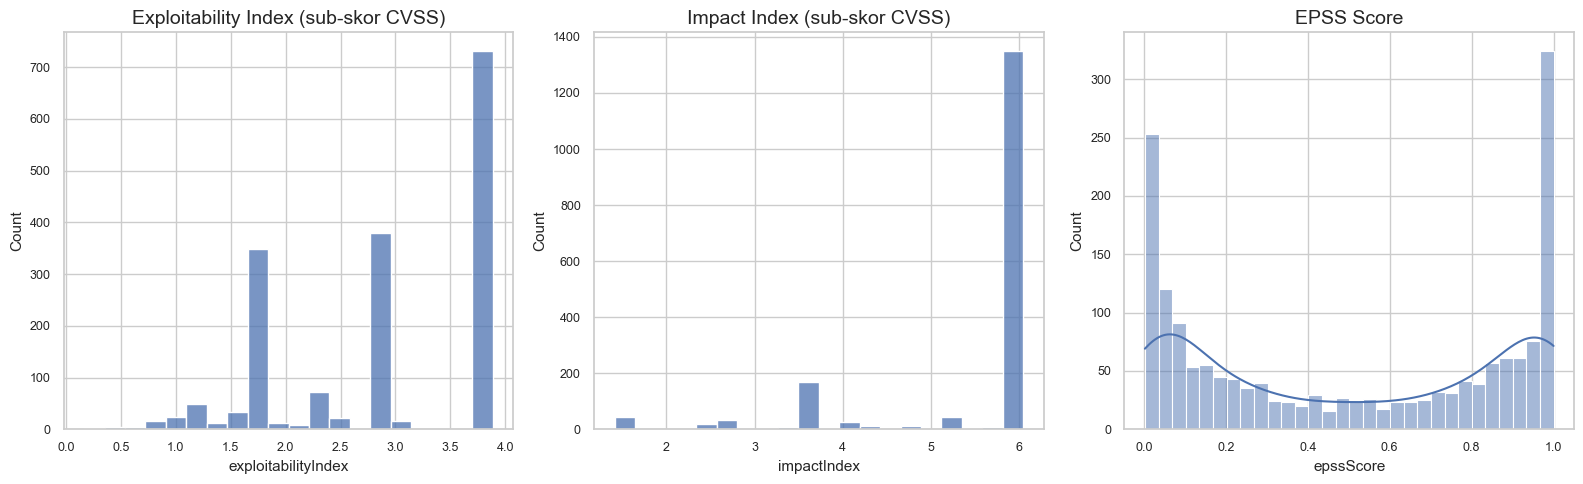

In [51]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.histplot(df_fe["exploitabilityIndex"], bins=20, ax=axes[0])
axes[0].set_title("Exploitability Index (sub-skor CVSS)")

sns.histplot(df_fe["impactIndex"], bins=20, ax=axes[1])
axes[1].set_title("Impact Index (sub-skor CVSS)")

sns.histplot(df_fe["epssScore"], bins=30, kde=True, ax=axes[2])
axes[2].set_title("EPSS Score")

plt.tight_layout()
plt.show()

### Pemeriksaan redundansi dan konsentrasi nilai

Dua pemeriksaan ini menjadi dasar keputusan fitur di atas:

1. **Redundansi `cvssScore`.** Jika `cvssScore` hampir seluruhnya bisa dijelaskan oleh dua sub-skor, memasukkannya ke K-Means hanya menghitung informasi yang sama lagi dan menenggelamkan EPSS.
2. **Konsentrasi nilai.** Fitur yang hampir konstan (satu nilai mendominasi) akan memiliki simpangan baku kecil. Setelah standardisasi, sedikit observasi yang berbeda menjadi sangat jauh (z-score ekstrem), dan K-Means cenderung memberi mereka cluster sendiri. Cluster seperti ini adalah **kantong outlier**, bukan profil risiko. Karena itu pemilihan K nanti memakai syarat ukuran cluster minimum dan stabilitas.

In [52]:
# 1) Seberapa besar cvssScore dijelaskan oleh dua sub-skor?
y = df_fe["cvssScore"].to_numpy(dtype=float)
A = np.column_stack([np.ones(len(df_fe)), df_fe["exploitabilityIndex"], df_fe["impactIndex"]])
coef, *_ = np.linalg.lstsq(A, y, rcond=None)
r2 = 1 - ((y - A @ coef) ** 2).sum() / ((y - y.mean()) ** 2).sum()
print(f"R2 cvssScore ~ exploitabilityIndex + impactIndex : {r2:.3f}")

print("\nKorelasi Spearman:")
display(df_fe[["cvssScore"] + FINAL_MODEL_FEATURES].corr(method="spearman").round(3))

# 2) Konsentrasi nilai dan jarak nilai terjauh (dalam z-score)
conc_rows = []
for col in FINAL_MODEL_FEATURES:
    s = df_fe[col]
    z = (s - s.mean()) / s.std()
    conc_rows.append({
        "fitur": col,
        "nilai_modus": s.round(3).value_counts().index[0],
        "proporsi_modus": s.round(3).value_counts(normalize=True).iloc[0],
        "z_minimum": z.min(),
        "z_maksimum": z.max(),
        "jumlah_|z|>3": int((z.abs() > 3).sum()),
    })
display(pd.DataFrame(conc_rows).round(3))

R2 cvssScore ~ exploitabilityIndex + impactIndex : 0.983

Korelasi Spearman:


,cvssScore,exploitabilityIndex,impactIndex,epssScore
cvssScore,1.000,0.653,0.627,0.368
exploitabilityIndex,0.653,1.000,-0.077,0.417
impactIndex,0.627,-0.077,1.000,0.069
epssScore,0.368,0.417,0.069,1.000


,fitur,nilai_modus,proporsi_modus,z_minimum,z_maksimum,jumlah_|z|>3
0,exploitabilityIndex,3.887,0.422,-2.853,1.023,0
1,impactIndex,5.873,0.688,-3.590,0.612,45
2,epssScore,1.000,0.057,-1.290,1.283,0


## 9.5 Standardization

`exploitabilityIndex` berada pada skala sekitar 0–3,9, `impactIndex` sekitar 0–6,1, dan `epssScore` pada 0–1. Sebelum K-Means, semua fitur distandardisasi agar satu fitur tidak mendominasi hanya karena skala angkanya lebih besar.

In [53]:
X = df_fe[FINAL_MODEL_FEATURES].astype(float).copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Mean setelah scaling:")
print(np.round(X_scaled.mean(axis=0), 6))
print("Std setelah scaling:")
print(np.round(X_scaled.std(axis=0), 6))

Mean setelah scaling:
[ 0.  0. -0.]
Std setelah scaling:
[1. 1. 1.]


## 9.6 Menentukan jumlah cluster (K)

Jumlah cluster **tidak ditetapkan secara asal**. Beberapa nilai K diuji pada grid **K = 2 sampai 12** (versi sebelumnya hanya sampai 8, sehingga K=8 bisa tampak "terbaik" hanya karena itu batas atas grid).

Untuk setiap K dihitung:

- **Silhouette** (lebih tinggi lebih baik), **Davies-Bouldin** (lebih rendah lebih baik), **Calinski-Harabasz** (lebih tinggi lebih baik), dan **inertia** untuk elbow;
- **proporsi cluster terkecil**: untuk mendeteksi kantong outlier;
- **stabilitas subsample**: data di-subsample 80% berulang kali, K-Means dilatih ulang, lalu hasilnya dibandingkan dengan cluster penuh memakai Adjusted Rand Index (ARI). ARI rendah berarti cluster berubah-ubah ketika data sedikit berbeda, tanda bahwa struktur itu tidak nyata.

In [54]:
K_MIN, K_MAX = 2, 12
N_BOOT = 20          # jumlah subsample per K
BOOT_FRAC = 0.80     # proporsi data per subsample

n_obs = len(X_scaled)
rng_boot = np.random.RandomState(42)

k_results = []
models_by_k = {}

for k in range(K_MIN, K_MAX + 1):
    model = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = model.fit_predict(X_scaled)
    models_by_k[k] = model

    cluster_share = np.bincount(labels, minlength=k) / n_obs

    boot_ari = []
    for b in range(N_BOOT):
        idx = rng_boot.choice(n_obs, size=int(BOOT_FRAC * n_obs), replace=False)
        model_b = KMeans(n_clusters=k, random_state=b, n_init=10).fit(X_scaled[idx])
        boot_ari.append(adjusted_rand_score(labels, model_b.predict(X_scaled)))

    k_results.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(X_scaled, labels),
        "davies_bouldin": davies_bouldin_score(X_scaled, labels),
        "calinski_harabasz": calinski_harabasz_score(X_scaled, labels),
        "min_cluster_share": cluster_share.min(),
        "bootstrap_ari_mean": float(np.mean(boot_ari)),
        "bootstrap_ari_min": float(np.min(boot_ari)),
    })

k_evaluation = pd.DataFrame(k_results)
display(k_evaluation.round(4))

best_k_silhouette = int(k_evaluation.loc[k_evaluation["silhouette"].idxmax(), "k"])
best_k_db = int(k_evaluation.loc[k_evaluation["davies_bouldin"].idxmin(), "k"])
best_k_ch = int(k_evaluation.loc[k_evaluation["calinski_harabasz"].idxmax(), "k"])

print(f"K terbaik menurut Silhouette       : {best_k_silhouette}")
print(f"K terbaik menurut Davies-Bouldin  : {best_k_db}")
print(f"K terbaik menurut Calinski-Harab.  : {best_k_ch}")

,k,inertia,silhouette,davies_bouldin,calinski_harabasz,min_cluster_share,bootstrap_ari_mean,bootstrap_ari_min
0,2,3394.0471,0.3748,1.1678,920.5451,0.4385,0.9623,0.9009
1,3,2118.5071,0.4398,0.8788,1257.7849,0.1766,0.9147,0.7152
2,4,1565.4831,0.4494,0.8485,1337.6810,0.1731,0.9988,0.9926
3,5,1187.4058,0.4988,0.7326,1459.4916,0.1725,0.9955,0.9845
4,6,900.1857,0.5251,0.7754,1649.4490,0.0750,0.9968,0.9887
5,7,791.1926,0.5272,0.8305,1602.6176,0.0381,0.9341,0.8672
6,8,682.9985,0.5426,0.7668,1629.3912,0.0358,0.9658,0.8031
7,9,589.2703,0.5421,0.8258,1685.8082,0.0381,0.9422,0.8701
8,10,501.7253,0.5563,0.7585,1792.3495,0.0254,0.9707,0.9388
9,11,459.8578,0.5581,0.7923,1774.6361,0.0190,0.9499,0.8707


K terbaik menurut Silhouette       : 11
K terbaik menurut Davies-Bouldin  : 5
K terbaik menurut Calinski-Harab.  : 10


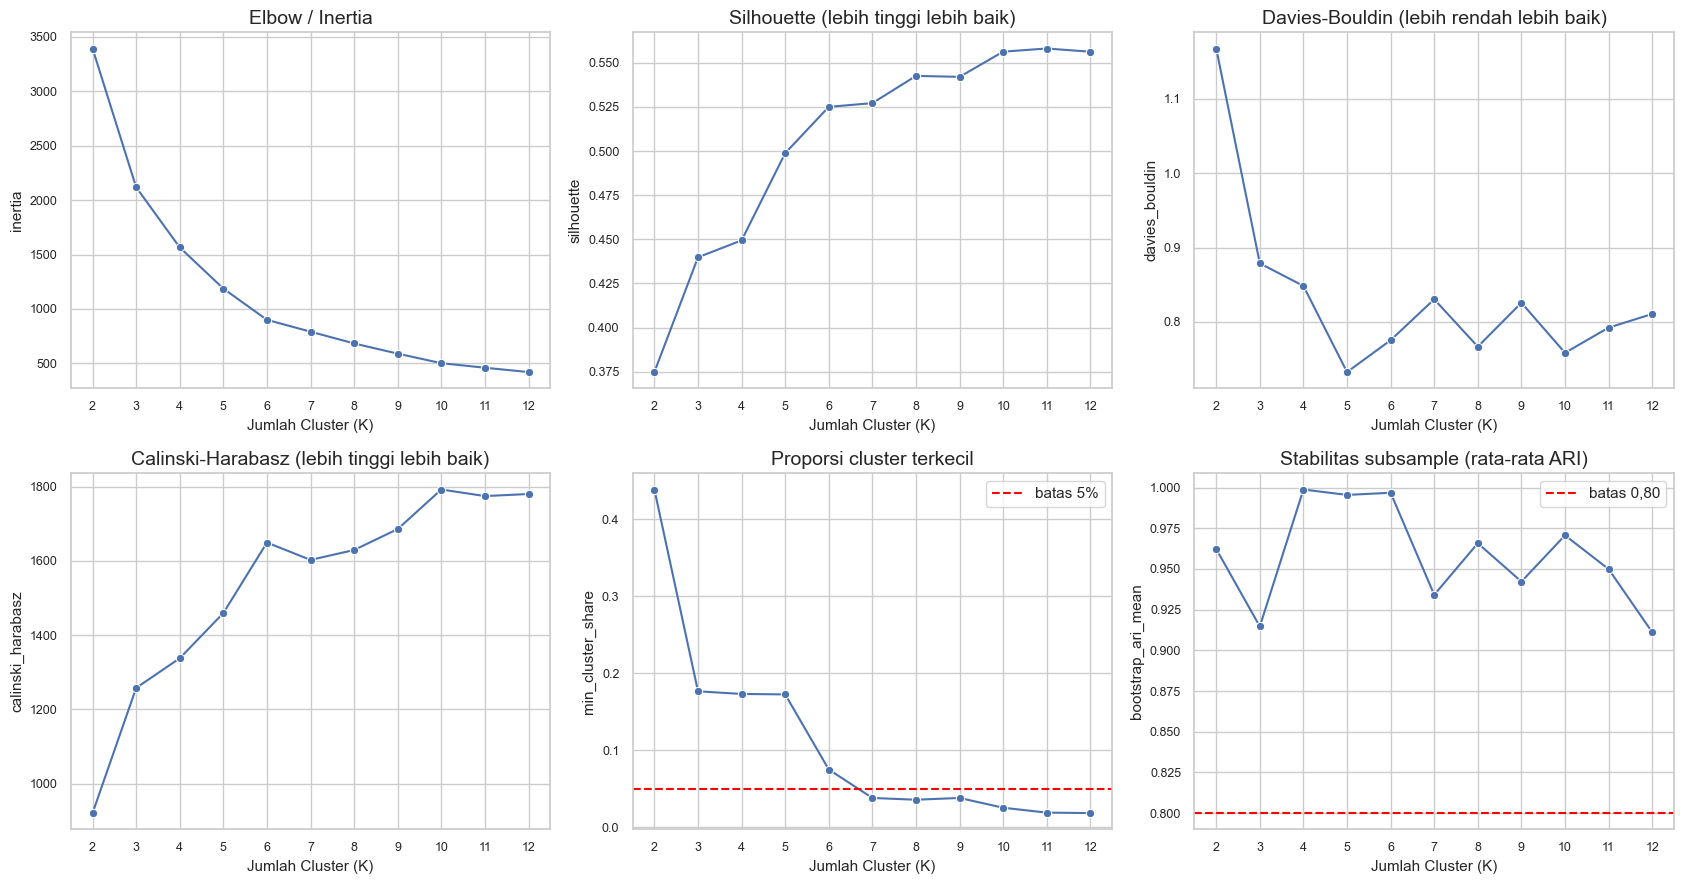

In [55]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))

sns.lineplot(data=k_evaluation, x="k", y="inertia", marker="o", ax=axes[0, 0])
axes[0, 0].set_title("Elbow / Inertia")

sns.lineplot(data=k_evaluation, x="k", y="silhouette", marker="o", ax=axes[0, 1])
axes[0, 1].set_title("Silhouette (lebih tinggi lebih baik)")

sns.lineplot(data=k_evaluation, x="k", y="davies_bouldin", marker="o", ax=axes[0, 2])
axes[0, 2].set_title("Davies-Bouldin (lebih rendah lebih baik)")

sns.lineplot(data=k_evaluation, x="k", y="calinski_harabasz", marker="o", ax=axes[1, 0])
axes[1, 0].set_title("Calinski-Harabasz (lebih tinggi lebih baik)")

sns.lineplot(data=k_evaluation, x="k", y="min_cluster_share", marker="o", ax=axes[1, 1])
axes[1, 1].axhline(0.05, color="red", linestyle="--", label="batas 5%")
axes[1, 1].set_title("Proporsi cluster terkecil")
axes[1, 1].legend()

sns.lineplot(data=k_evaluation, x="k", y="bootstrap_ari_mean", marker="o", ax=axes[1, 2])
axes[1, 2].axhline(0.80, color="red", linestyle="--", label="batas 0,80")
axes[1, 2].set_title("Stabilitas subsample (rata-rata ARI)")
axes[1, 2].legend()

for ax in axes.ravel():
    ax.set_xlabel("Jumlah Cluster (K)")
    ax.set_xticks(range(K_MIN, K_MAX + 1))

plt.tight_layout()
plt.show()

### Keputusan jumlah K

Versi sebelumnya otomatis mengambil K dengan silhouette tertinggi pada grid 2–8. Itu bermasalah: silhouette bisa terus naik ketika K membesar karena cluster kecil yang terpisah jauh (kantong outlier) ikut dihitung sebagai "cluster yang rapi", sementara metrik lain (Davies-Bouldin, Calinski-Harabasz) menunjuk K yang berbeda.

Aturan keputusan berikut ditetapkan **sebelum** melihat hasil:

1. K kandidat harus lolos dua syarat: **tidak ada cluster di bawah 5% populasi** dan **stabilitas subsample (rata-rata ARI) ≥ 0,80**.
2. Di antara kandidat, dipilih **K terkecil yang sudah tidak memberi peningkatan silhouette berarti**: silhouette pada dua K berikutnya tidak lebih tinggi dari silhouette K tersebut lebih dari 0,02. Ini prinsip parsimoni (diminishing returns). Fitur CVSS bersifat diskrit, sehingga silhouette cenderung terus naik walau K ditambah; tanpa aturan ini, "silhouette tertinggi" hampir selalu jatuh di batas atas grid.
3. Davies-Bouldin dan Calinski-Harabasz tetap dilaporkan sebagai pendukung, tetapi tidak dipakai sebagai pemutus otomatis. Jika ketiganya tidak sepakat, itu dibahas pada kesimpulan.
4. Jika tidak ada K yang lolos, notebook memilih K dengan stabilitas tertinggi dan menampilkan peringatan; artinya struktur cluster pada data ini lemah.
5. Jika K terpilih sama dengan batas atas grid, notebook menampilkan peringatan bahwa grid mungkin masih terpotong.
6. `FINAL_K_OVERRIDE` disediakan bila ingin menguji K lain secara manual; nilai bawaannya `None` (pakai aturan di atas).

Hasil akhirnya **muncul dari data saat notebook dijalankan**, bukan ditetapkan di awal.

## 9.7 Pelatihan K-Means Final

In [56]:
MIN_CLUSTER_SHARE = 0.05
MIN_STABILITY_ARI = 0.80
SIL_MIN_GAIN = 0.02          # peningkatan silhouette minimal agar K tambahan dianggap bermanfaat
FINAL_K_OVERRIDE = None      # isi angka (mis. 4) hanya bila ingin menguji K lain secara manual

eligible = k_evaluation[
    (k_evaluation["min_cluster_share"] >= MIN_CLUSTER_SHARE)
    & (k_evaluation["bootstrap_ari_mean"] >= MIN_STABILITY_ARI)
].copy()

sil_by_k = k_evaluation.set_index("k")["silhouette"]


def silhouette_gain_ahead(k):
    # Peningkatan silhouette terbesar yang bisa didapat dalam 2 langkah K ke depan
    ahead = [sil_by_k[j] for j in (k + 1, k + 2) if j in sil_by_k.index]
    return (max(ahead) - sil_by_k[k]) if ahead else 0.0


if eligible.empty:
    selected_k = int(k_evaluation.loc[k_evaluation["bootstrap_ari_mean"].idxmax(), "k"])
    print("PERINGATAN: tidak ada K yang lolos syarat ukuran cluster dan stabilitas.")
    print(f"Dipilih K dengan stabilitas tertinggi: K = {selected_k}. Interpretasikan dengan hati-hati.")
else:
    eligible["gain_2_langkah_ke_depan"] = eligible["k"].map(silhouette_gain_ahead)
    display(eligible[["k", "silhouette", "davies_bouldin", "calinski_harabasz",
                      "min_cluster_share", "bootstrap_ari_mean", "gain_2_langkah_ke_depan"]].round(4))
    plateau = eligible[eligible["gain_2_langkah_ke_depan"] < SIL_MIN_GAIN]
    if plateau.empty:
        selected_k = int(eligible.loc[eligible["silhouette"].idxmax(), "k"])
        print("Silhouette belum mendatar di dalam grid; dipilih silhouette tertinggi di antara kandidat.")
    else:
        selected_k = int(plateau["k"].min())
        print(f"K terkecil yang tidak lagi memberi peningkatan silhouette > {SIL_MIN_GAIN}: K = {selected_k}")

if selected_k == K_MAX:
    print(f"PERINGATAN: K terpilih sama dengan batas atas grid (K_MAX = {K_MAX}); perluas grid bila perlu.")

FINAL_K = FINAL_K_OVERRIDE if FINAL_K_OVERRIDE is not None else selected_k

kmeans_final = KMeans(
    n_clusters=FINAL_K,
    random_state=42,
    n_init=20,
)
cluster_labels = kmeans_final.fit_predict(X_scaled)
df_fe["cluster"] = cluster_labels

print(f"\nModel K-Means final menggunakan K = {FINAL_K}")

,k,silhouette,davies_bouldin,calinski_harabasz,min_cluster_share,bootstrap_ari_mean,gain_2_langkah_ke_depan
0,2,0.3748,1.1678,920.5451,0.4385,0.9623,0.0746
1,3,0.4398,0.8788,1257.7849,0.1766,0.9147,0.0590
2,4,0.4494,0.8485,1337.6810,0.1731,0.9988,0.0757
3,5,0.4988,0.7326,1459.4916,0.1725,0.9955,0.0283
4,6,0.5251,0.7754,1649.4490,0.0750,0.9968,0.0175


K terkecil yang tidak lagi memberi peningkatan silhouette > 0.02: K = 6

Model K-Means final menggunakan K = 6


## 9.8 Evaluasi kualitas cluster

In [57]:
overall_silhouette = silhouette_score(X_scaled, df_fe["cluster"])
db_score = davies_bouldin_score(X_scaled, df_fe["cluster"])
ch_score = calinski_harabasz_score(X_scaled, df_fe["cluster"])
sil_samples = silhouette_samples(X_scaled, df_fe["cluster"])
df_fe["silhouette"] = sil_samples

cluster_quality = (
    df_fe.groupby("cluster")
    .agg(
        n=("cveID", "count"),
        proporsi=("cveID", lambda s: len(s) / len(df_fe)),
        mean_silhouette=("silhouette", "mean"),
        median_silhouette=("silhouette", "median"),
        proporsi_silhouette_negatif=("silhouette", lambda s: (s < 0).mean()),
    )
    .reset_index()
)

print(f"Silhouette overall : {overall_silhouette:.4f}")
print(f"Davies-Bouldin     : {db_score:.4f}")
print(f"Calinski-Harabasz  : {ch_score:.2f}")
display(cluster_quality)

Silhouette overall : 0.5251
Davies-Bouldin     : 0.7754
Calinski-Harabasz  : 1649.45


,cluster,n,proporsi,mean_silhouette,median_silhouette,proporsi_silhouette_negatif
0,0,183,0.105597,0.306542,0.337045,0.010929
1,1,347,0.200231,0.430064,0.419358,0.008646
2,2,427,0.246394,0.777997,0.859965,0.000000
3,3,130,0.075014,0.413106,0.478266,0.000000
4,4,303,0.174841,0.360156,0.310361,0.029703
5,5,343,0.197923,0.611003,0.691879,0.000000


## 9.9 Stabilitas cluster

Ada dua pemeriksaan berbeda:

- **Antar-seed (inisialisasi).** Dengan `n_init=20`, K-Means hampir selalu menemukan solusi yang sama, sehingga ARI mendekati 1. Ini hanya menguji optimizer, **bukan** apakah cluster itu nyata.
- **Antar-subsample.** Data di-subsample 80% berulang kali, model dilatih ulang, lalu dibandingkan dengan cluster penuh. Ini menguji apakah struktur cluster bertahan ketika datanya sedikit berubah. Pemeriksaan inilah yang bermakna: ARI di atas 0,80 menandakan stabil, sedangkan di bawah sekitar 0,60 menandakan cluster tidak dapat diandalkan.

In [58]:
# (a) Stabilitas antar-seed: hanya menguji optimizer
seed_ari = []
for seed in range(10):
    model_seed = KMeans(n_clusters=FINAL_K, random_state=seed, n_init=20)
    labels_seed = model_seed.fit_predict(X_scaled)
    seed_ari.append(adjusted_rand_score(df_fe["cluster"], labels_seed))

# (b) Stabilitas antar-subsample: menguji apakah struktur cluster nyata
rng_stab = np.random.RandomState(2024)
sub_ari = []
for b in range(30):
    idx = rng_stab.choice(len(X_scaled), size=int(0.8 * len(X_scaled)), replace=False)
    model_b = KMeans(n_clusters=FINAL_K, random_state=b, n_init=10).fit(X_scaled[idx])
    sub_ari.append(adjusted_rand_score(df_fe["cluster"], model_b.predict(X_scaled)))

stability_summary = pd.DataFrame({
    "pemeriksaan": ["antar-seed (optimizer)", "antar-subsample 80% (struktur)"],
    "mean_ARI": [np.mean(seed_ari), np.mean(sub_ari)],
    "median_ARI": [np.median(seed_ari), np.median(sub_ari)],
    "min_ARI": [np.min(seed_ari), np.min(sub_ari)],
})
display(stability_summary.round(4))

,pemeriksaan,mean_ARI,median_ARI,min_ARI
0,antar-seed (optimizer),1.0000,1.0000,1.0000
1,antar-subsample 80% (struktur),0.9968,0.9973,0.9903


## 9.10 Centroid cluster pada skala asli

Centroid dikembalikan ke skala asli agar lebih mudah ditafsirkan daripada nilai z-score.

In [59]:
centroids_scaled = kmeans_final.cluster_centers_
centroids_original = scaler.inverse_transform(centroids_scaled)
centroids = pd.DataFrame(centroids_original, columns=FINAL_MODEL_FEATURES)
centroids.index.name = "cluster"
display(centroids.round(4))

,exploitabilityIndex,impactIndex,epssScore
cluster,,,
0,2.8409,3.1545,0.1345
1,3.2973,5.8676,0.1845
2,3.8707,5.8511,0.9169
3,3.6157,3.2031,0.8408
4,2.1739,5.8602,0.8033
5,1.7155,5.8486,0.1116


## 9.11 Visualisasi cluster

`cvssScore` tidak dipakai membentuk cluster, sehingga plot CVSS–EPSS di bawah berfungsi sebagai **validasi eksternal**: bila cluster terpisah juga pada CVSS, itu karena sub-skor exploitability dan impact memang membawa informasi severity. Panel kedua menunjukkan ruang fitur yang benar-benar dipakai model (exploitability vs EPSS). Tanda X adalah **rata-rata tiap cluster**.

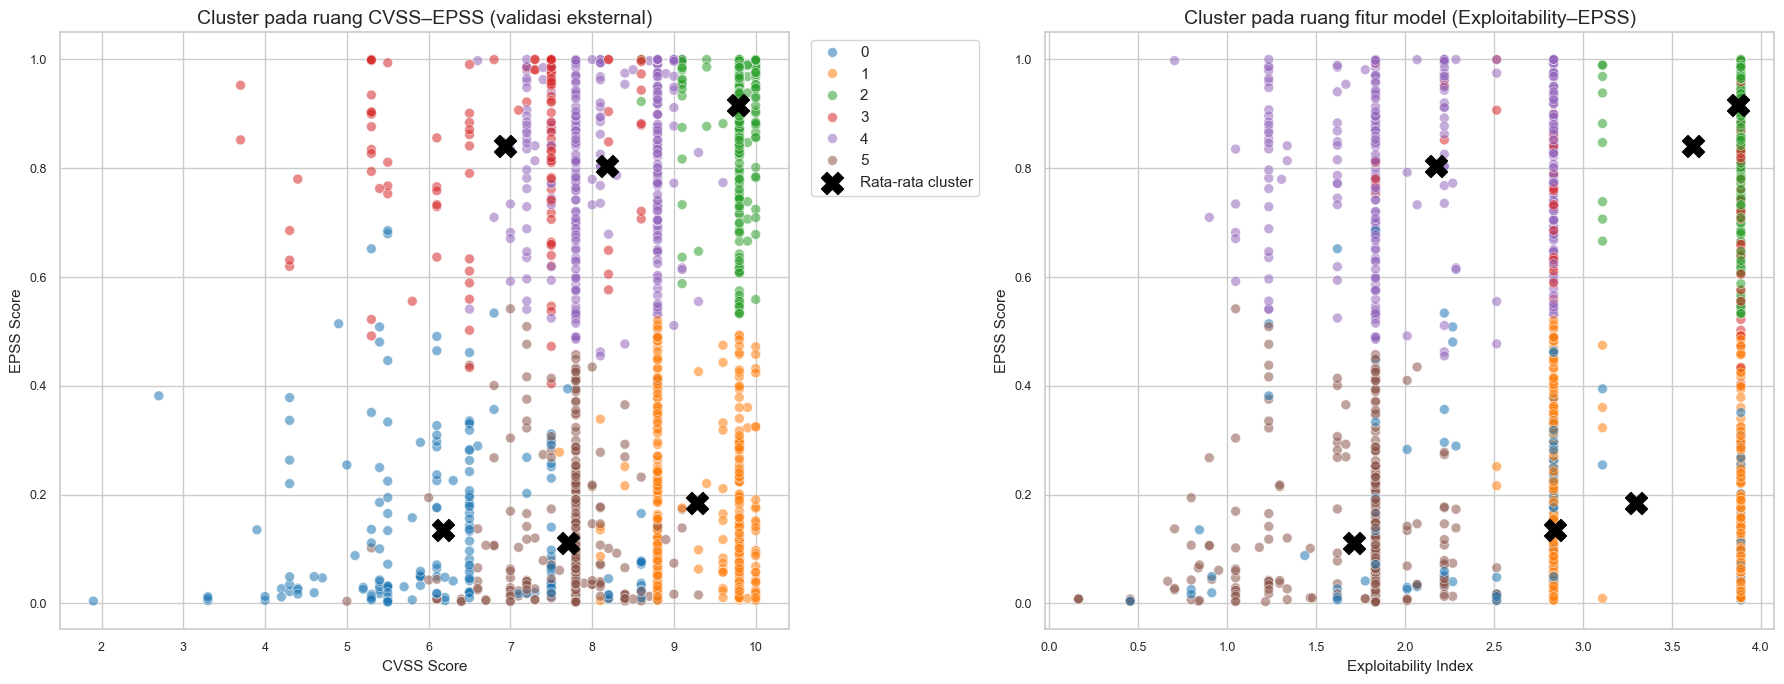

In [60]:
palette_name = "tab10" if FINAL_K <= 10 else "tab20"
cluster_means = df_fe.groupby("cluster")[["cvssScore", "epssScore", "exploitabilityIndex", "impactIndex"]].mean()

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.scatterplot(
    data=df_fe, x="cvssScore", y="epssScore", hue="cluster",
    palette=palette_name, alpha=0.55, s=50, ax=axes[0],
)
axes[0].scatter(
    cluster_means["cvssScore"], cluster_means["epssScore"],
    marker="X", s=250, edgecolor="black", linewidth=1, color="black", label="Rata-rata cluster",
)
axes[0].set_title("Cluster pada ruang CVSS–EPSS (validasi eksternal)")
axes[0].set_xlabel("CVSS Score")
axes[0].set_ylabel("EPSS Score")
axes[0].legend(bbox_to_anchor=(1.02, 1), loc="upper left")

sns.scatterplot(
    data=df_fe, x="exploitabilityIndex", y="epssScore", hue="cluster",
    palette=palette_name, alpha=0.55, s=50, ax=axes[1], legend=False,
)
axes[1].scatter(
    cluster_means["exploitabilityIndex"], cluster_means["epssScore"],
    marker="X", s=250, edgecolor="black", linewidth=1, color="black",
)
axes[1].set_title("Cluster pada ruang fitur model (Exploitability–EPSS)")
axes[1].set_xlabel("Exploitability Index")
axes[1].set_ylabel("EPSS Score")

plt.tight_layout()
plt.show()

## 9.12 Profiling Cluster

K-Means hanya memberikan label `Cluster 0`, `Cluster 1`, dan seterusnya. Agar berguna bagi analisis keamanan, kita kembali ke data asli dan menerjemahkan tiap cluster berdasarkan:

- rata-rata/median CVSS dan EPSS;
- exploitability index dan impact index;
- karakteristik serangan yang dominan, **beserta proporsinya di dalam cluster** (mis. `NONE (92%)`), karena label dominan saja tidak menunjukkan seberapa murni cluster tersebut;
- proporsi ransomware yang ditandai `Known`;
- vendor dan product yang dominan.

Label tinggi/sedang/rendah pada `ringkasan_profil` dihitung dari **rata-rata cluster dibanding rata-rata global dalam satuan simpangan baku** (≥ +0,5 SD = tinggi, ≤ −0,5 SD = rendah, selain itu sedang). Versi sebelumnya membandingkan rata-rata cluster dengan *median* global, dan pada fitur yang hampir konstan perbandingan itu tidak informatif.

**Jangan menentukan nama cluster sebelum melihat tabel profiling.** Nama profil harus lahir dari karakteristik nyata hasil model.

In [61]:
def safe_mode(series):
    # Nilai dominan beserta proporsinya di dalam cluster, mis. "NONE (92%)"
    values = series.dropna().astype(str)
    if values.empty:
        return "N/A"
    shares = values.value_counts(normalize=True)
    return f"{shares.index[0]} ({shares.iloc[0]:.0%})"


PROFILE_NUMERIC = ["cvssScore"] + FINAL_MODEL_FEATURES
global_mean = df_fe[PROFILE_NUMERIC].mean()
global_std = df_fe[PROFILE_NUMERIC].std()


def level_label(value, name):
    z = (value - global_mean[name]) / global_std[name]
    return "tinggi" if z >= 0.5 else ("rendah" if z <= -0.5 else "sedang")


profile_rows = []
for cluster_id, grp in df_fe.groupby("cluster"):
    raw_grp = df_analysis[df_analysis["cveID"].isin(grp["cveID"])].copy()

    ransomware_known = (
        raw_grp["knownRansomwareCampaignUse"].astype("string").str.upper().eq("KNOWN").sum()
        if "knownRansomwareCampaignUse" in raw_grp.columns else np.nan
    )

    row = {
        "cluster": cluster_id,
        "jumlah_CVE": len(grp),
        "proporsi": len(grp) / len(df_fe),
        "median_cvss": grp["cvssScore"].median(),
        "mean_cvss": grp["cvssScore"].mean(),
        "median_epss": grp["epssScore"].median(),
        "mean_epss": grp["epssScore"].mean(),
        "mean_exploitability": grp["exploitabilityIndex"].mean(),
        "mean_impact": grp["impactIndex"].mean(),
        "ransomware_known_count": int(ransomware_known) if pd.notna(ransomware_known) else np.nan,
        "ransomware_known_rate": (
            float(ransomware_known / len(raw_grp)) if pd.notna(ransomware_known) and len(raw_grp) else np.nan
        ),
        "attackVector_dominan": safe_mode(raw_grp["attackVector"]),
        "attackComplexity_dominan": safe_mode(raw_grp["attackComplexity"]),
        "privilegesRequired_dominan": safe_mode(raw_grp["privilegesRequired"]),
        "userInteraction_dominan": safe_mode(raw_grp["userInteraction"]),
        "scope_dominan": safe_mode(raw_grp["scope"]),
        "confidentiality_dominan": safe_mode(raw_grp["confidentialityImpact"]),
        "integrity_dominan": safe_mode(raw_grp["integrityImpact"]),
        "availability_dominan": safe_mode(raw_grp["availabilityImpact"]),
        "vendor_terbanyak": safe_mode(raw_grp["vendorProject"]),
        "product_terbanyak": safe_mode(raw_grp["product"]),
    }

    row["ringkasan_profil"] = " | ".join([
        f"CVSS {level_label(grp['cvssScore'].mean(), 'cvssScore')}",
        f"EPSS {level_label(grp['epssScore'].mean(), 'epssScore')}",
        f"exploitability {level_label(grp['exploitabilityIndex'].mean(), 'exploitabilityIndex')}",
        f"impact {level_label(grp['impactIndex'].mean(), 'impactIndex')}",
    ])

    profile_rows.append(row)

cluster_profile = pd.DataFrame(profile_rows).sort_values("cluster").reset_index(drop=True)
display(cluster_profile.round(4))

,cluster,jumlah_CVE,proporsi,median_cvss,mean_cvss,median_epss,mean_epss,mean_exploitability,mean_impact,ransomware_known_count,...,attackComplexity_dominan,privilegesRequired_dominan,userInteraction_dominan,scope_dominan,confidentiality_dominan,integrity_dominan,availability_dominan,vendor_terbanyak,product_terbanyak,ringkasan_profil
0,0,183,0.1056,6.1,6.1787,0.0706,0.1345,2.8409,3.1545,20,...,LOW (91%),NONE (73%),NONE (70%),UNCHANGED (75%),NONE (42%),NONE (63%),NONE (68%),Cisco (21%),Windows (7%),CVSS rendah | EPSS rendah | exploitability sed...
1,1,347,0.2002,8.8,9.2772,0.1467,0.1845,3.2973,5.8676,37,...,LOW (100%),NONE (84%),NONE (61%),UNCHANGED (85%),HIGH (99%),HIGH (99%),HIGH (97%),Google (17%),Chromium V8 (10%),CVSS tinggi | EPSS rendah | exploitability sed...
2,2,427,0.2464,9.8,9.7836,0.9707,0.9169,3.8707,5.8511,132,...,LOW (100%),NONE (98%),NONE (100%),UNCHANGED (86%),HIGH (99%),HIGH (99%),HIGH (93%),Oracle (6%),Multiple Products (4%),CVSS tinggi | EPSS tinggi | exploitability tin...
3,3,130,0.0750,7.5,6.9377,0.8781,0.8408,3.6157,3.2031,31,...,LOW (98%),NONE (95%),NONE (88%),UNCHANGED (85%),HIGH (56%),NONE (70%),NONE (86%),Microsoft (12%),ColdFusion (4%),CVSS rendah | EPSS tinggi | exploitability tin...
4,4,303,0.1748,8.1,8.1782,0.8270,0.8033,2.1739,5.8602,80,...,LOW (81%),NONE (64%),REQUIRED (52%),UNCHANGED (90%),HIGH (99%),HIGH (99%),HIGH (95%),Microsoft (45%),Windows (15%),CVSS sedang | EPSS tinggi | exploitability ren...
5,5,343,0.1979,7.8,7.7085,0.0556,0.1116,1.7155,5.8486,61,...,LOW (81%),LOW (61%),NONE (76%),UNCHANGED (89%),HIGH (98%),HIGH (98%),HIGH (96%),Microsoft (44%),Windows (29%),CVSS rendah | EPSS rendah | exploitability ren...


## 9.13 Contoh cara membaca isi setiap cluster

Misalnya **hasil nyata** nanti menunjukkan:

- Cluster A: CVSS tinggi + EPSS tinggi + exploitability tinggi → dapat diberi interpretasi seperti **High-Severity, Highly Exploitable Profile**.
- Cluster B: CVSS tinggi + EPSS rendah + exploitability rendah → **Severe but Less Exploitable Profile**.
- Cluster C: CVSS sedang + EPSS tinggi + exploitability tinggi → **Moderate-Severity, High-Exploitability Profile**.

**Ini hanya contoh cara membaca. Jangan memasukkan nama tersebut sebagai hasil penelitian sebelum tabel `cluster_profile` benar-benar menunjukkan pola itu.** Perhatikan juga kolom `*_dominan` dan proporsinya: cluster dengan CVSS tinggi seharusnya didominasi `userInteraction = NONE` dan `privilegesRequired = NONE`. Jika tidak, periksa kembali cleaning.

## 9.14 Profiling tambahan dengan variabel yang tidak membentuk cluster

Variabel seperti vendor, product, CWE, dan tanggal **tidak dipakai untuk menentukan kedekatan K-Means**, tetapi bisa digunakan untuk memahami konteks tiap profil. Hal ini menjaga model tetap fokus pada karakteristik risiko, sekaligus mempertahankan manfaat seluruh isi tiga tabel.

In [62]:
# Menambahkan label cluster ke salinan data gabungan untuk profiling.
df_profile = df_analysis.merge(
    df_fe[["cveID", "cluster"]],
    on="cveID",
    how="inner",
    validate="one_to_one"
)

vendor_profile = (
    df_profile.dropna(subset=["vendorProject"])
    .groupby(["cluster", "vendorProject"])
    .size()
    .reset_index(name="jumlah_CVE")
    .sort_values(["cluster", "jumlah_CVE"], ascending=[True, False])
    .groupby("cluster")
    .head(5)
)

product_profile = (
    df_profile.dropna(subset=["product"])
    .groupby(["cluster", "product"])
    .size()
    .reset_index(name="jumlah_CVE")
    .sort_values(["cluster", "jumlah_CVE"], ascending=[True, False])
    .groupby("cluster")
    .head(5)
)

print("Top vendor per cluster:")
display(vendor_profile)
print("Top product per cluster:")
display(product_profile)

Top vendor per cluster:


,cluster,vendorProject,jumlah_CVE
7,0,Cisco,38
27,0,Microsoft,30
3,0,Apple,17
45,0,Synacor,8
11,0,Fortinet,6
89,1,Google,58
63,1,Apple,37
106,1,Microsoft,37
72,1,Cisco,23
59,1,Adobe,20


Top product per cluster:


,cluster,product,jumlah_CVE
100,0,Windows,13
66,0,Multiple Products,9
105,0,Zimbra Collaboration Suite (ZCS),7
44,0,IOS XR,5
46,0,IOS and IOS XE Software,5
153,1,Chromium V8,33
228,1,Multiple Products,30
185,1,Flash Player,11
199,1,IOS and IOS XE Software,8
203,1,Internet Explorer,8


## 9.15 Distribusi ukuran cluster

,jumlah_CVE,proporsi
cluster,,
0,183,0.105597
1,347,0.200231
2,427,0.246394
3,130,0.075014
4,303,0.174841
5,343,0.197923


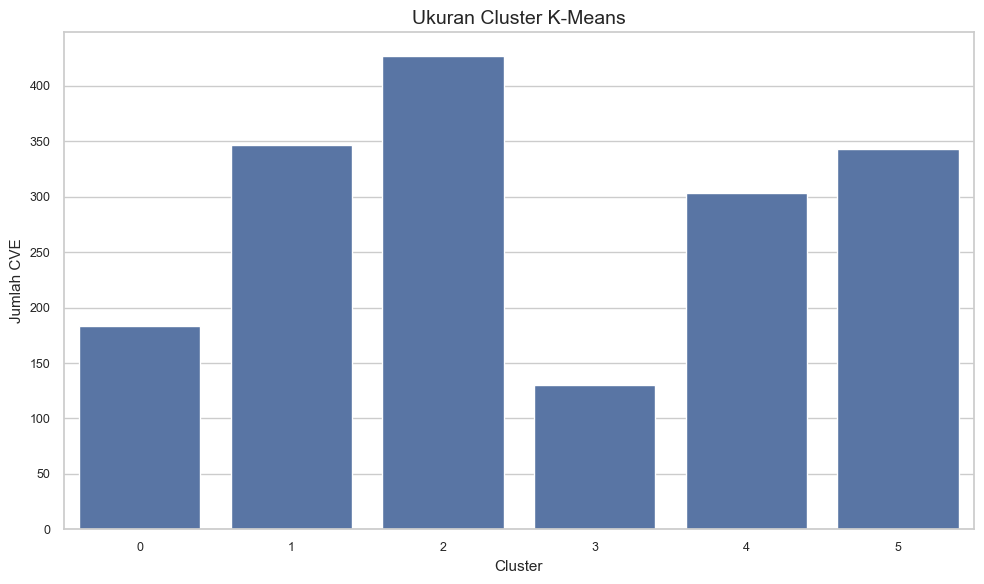

In [63]:
cluster_size = (
    df_fe["cluster"]
    .value_counts()
    .sort_index()
    .rename("jumlah_CVE")
    .to_frame()
)
cluster_size["proporsi"] = cluster_size["jumlah_CVE"] / len(df_fe)

display(cluster_size)

plt.figure(figsize=(10, 6))
sns.barplot(data=cluster_size.reset_index(), x="cluster", y="jumlah_CVE")
plt.title("Ukuran Cluster K-Means")
plt.xlabel("Cluster")
plt.ylabel("Jumlah CVE")
plt.tight_layout()
plt.show()

## 9.16 Kesimpulan Model AI

Tuliskan setelah notebook dijalankan:

1. **K optimal:** nilai K yang dipilih, beserta alasannya berdasarkan aturan di 9.6 (ukuran cluster minimum, stabilitas subsample, dan silhouette yang sudah mendatar). Sebutkan juga bila Davies-Bouldin dan Calinski-Harabasz menunjuk K yang berbeda.
2. **Kualitas clustering:** Silhouette, Davies-Bouldin, Calinski-Harabasz, serta ARI antar-subsample (bukan hanya antar-seed).
3. **Profil tiap cluster:** jelaskan CVSS, EPSS, exploitability, impact, dan karakteristik teknis dominan beserta proporsinya.
4. **Konteks:** gunakan `knownRansomwareCampaignUse`, vendor/product, CWE, dan variabel lain untuk memperkaya interpretasi setelah cluster terbentuk.
5. **Keterbatasan:** jika silhouette keseluruhan rendah atau stabilitas lemah, nyatakan bahwa populasi KEV lebih mirip kontinum risiko dengan beberapa gerombol longgar daripada kelompok yang terpisah tegas. Itu juga temuan yang sah.
6. **Implikasi:** clustering membantu membedakan profil vulnerability yang sama-sama telah terbukti dieksploitasi, bukan memprediksi apakah eksploitasi akan terjadi.

---

### Urutan notebook final

```text
1. Identitas Proyek
2. Pertanyaan Bisnis
3. Import
4. Data Wrangling
   ├── Gathering
   ├── Assessing
   └── Cleaning
5. EDA
   ├── Q1
   ├── Q2
   ├── Q3
   └── Q4  ← dijawab dulu lewat EDA
6. Visualization & Explanatory Analysis
7. Analisis Lanjutan (Opsional)
8. Conclusion  ← kesimpulan EDA
9. Model AI
   ├── Feature Selection (10 raw variables Q4)
   ├── Feature Engineering
   ├── Standardization
   ├── K-Means
   ├── Evaluasi K
   ├── Evaluasi kualitas
   └── Profiling & interpretation
```

**Catatan model:** dari 10 raw variables, fitur pembentuk K-Means diringkas menjadi `exploitabilityIndex` dan `impactIndex` (sub-skor resmi CVSS v3.x) serta `epssScore`. `cvssScore` dan `knownRansomwareCampaignUse` dipakai sebagai variabel validasi/profiling. PCA tidak digunakan pada pipeline utama.


---

### Lampiran — Log perbaikan versi (2)

| Bagian | Masalah pada versi sebelumnya | Perbaikan |
|---|---|---|
| 4.3 Cleaning | `"NONE"` diubah menjadi missing; 3.145 sel NVD yang sebenarnya valid menjadi kosong | `NONE` tidak lagi dianggap missing; ditambah verifikasi jumlah `NONE` sebelum dan sesudah cleaning |
| EDA Q3 dan Q4 | `dropna()` membuang semua baris `NONE`, sehingga hanya 22–26 baris yang tersisa dan hanya muncul kategori `REQUIRED` | Semua CVE terpakai; ditambah `assert` bahwa tidak ada baris terbuang |
| 9.2 Data model | Kategori yang kosong diisi modus, mengubah `NONE` menjadi `REQUIRED`/`LOW`/`HIGH` | Tidak ada imputasi kategori; bila ada missing sungguhan, notebook berhenti |
| 9.3 Feature engineering | Rata-rata ordinal buatan; `cvssScore` ikut dengan dua index sehingga info yang sama dihitung tiga kali; `scope` tidak dipakai | Sub-skor resmi CVSS v3.x (termasuk `scope`), `cvssScore` dikeluarkan dari input model; validasi dengan menghitung ulang base score |
| 9.6 Pemilihan K | Grid hanya 2–8 dan otomatis mengambil silhouette tertinggi (K=8 adalah batas grid) | Grid 2–12, syarat cluster ≥ 5% dan stabilitas subsample ≥ 0,80, lalu K terkecil yang silhouette-nya sudah mendatar |
| 9.9 Stabilitas | ARI antar-seed ≈ 1 (hanya menguji optimizer) | Ditambah ARI antar-subsample |
| 9.12 Profiling | Cluster mean dibandingkan dengan median global; label dominan tanpa proporsi | Perbandingan dalam SD terhadap rata-rata global; proporsi ditampilkan |

Seluruh output sel setelah tahap cleaning sengaja dikosongkan karena hasil lama berasal dari data yang rusak. Jalankan ulang notebook dari atas (Run All).